# Phi-4-multimodal


In [1]:
CHEMIN_PDF = "/kaggle/input/datasets/eyajall/communication/Chapitre_4_Parties_Prenantes_Communication_Risques.pdf"
CHEMIN_AUDIO = "/kaggle/input/datasets/eyajall/communication/Voix_261123_202702.mp3"

# --- Modèle ---
MODEL_ID = "microsoft/Phi-4-multimodal-instruct"
REVISION = "refs/pr/70"              # version du dépôt au format Transformers (la branche principale ne marche qu'avec trust_remote_code)
ADAPTATEUR_ECOUTE = "speech"         # étape 1 : audio seul → mode « parole » de Phi-4 (celui entraîné pour comprendre la voix)
ADAPTATEUR_VERIFICATION = "vision"   # étape 2 : pages du cours (images + texte) → mode « vision » de Phi-4
RESERVE_ACTIVATIONS_GIO = 3.0        # mémoire laissée libre sur chaque GPU pour les calculs

# --- Pages du PDF ---
PAGES_A_ANALYSER = None              # None = les 31 pages sont candidates ; ex. "14-20" pour limiter
PAGES_PAR_AFFIRMATION = 2            # nombre de pages (les plus proches de l'affirmation) montrées au modèle pour la vérifier
# Phi-4 découpe chaque image en tuiles de 448 x 448 px (+ une vue d'ensemble). Largeur de rendu d'une page 16:9 :
#   896 px  → ≈ 870 tokens par page | 1344 px → ≈ 1 600 tokens (texte et tableaux bien lisibles) | 1792 px → ≈ 2 600 tokens
LARGEUR_PAGE_PX = 1344
AJOUTER_TEXTE_PDF = True             # ajoute sous chaque image le texte de la page extrait du PDF
MAX_CARACTERES_TEXTE_PAGE = 3000

# --- Audio ---
NORMALISER_VOLUME = True             # remonte le volume de la version envoyée au modèle (crête à 0,9)
AUDIO_DANS_VERIFICATION = False      # True : renvoie aussi l'audio à l'étape 2 (mode « vision-speech », moins fiable)

# --- Génération ---
MAX_TOKENS_ECOUTE = 600              # longueur max de ce que le modèle écrit en écoutant
MAX_TOKENS_VERIFICATION = 400        # longueur max de la vérification d'UNE affirmation
ECHANTILLONNAGE = False              # False = décodage glouton, réponse déterministe
AFFICHER_EN_DIRECT = True

# --- Évaluation ---
TRANSCRIPTION_REFERENCE = None       # facultatif : ce que tu as réellement dit (texte) → taux d'erreur de mots de l'écoute (WER)
INTERVALLE_MESURE_S = 0.5            # fréquence des mesures GPU / CPU / RAM pendant l'exécution

DOSSIER_ENTREES = "/kaggle/input"
DOSSIER_TRAVAIL = "/kaggle/working/analyse_phi4"

## 2. Vérification du GPU

In [2]:
import os, sys, shutil, subprocess, json, time, gc, math, re, hashlib, warnings
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # limite la fragmentation mémoire GPU
import torch

# Dossier de sortie (images des pages, audio préparé, résultats)
os.makedirs(DOSSIER_TRAVAIL, exist_ok=True)


def mesurer_memoire_libre(gpus):
    """Met à jour la mémoire libre/totale (en Gio) de chaque GPU de la liste."""
    for g in gpus:
        libre, total = torch.cuda.mem_get_info(g["index"])
        g["libre_gio"], g["total_gio"] = libre / 2**30, total / 2**30
    return gpus


def liberer_memoire():
    """Libère la mémoire GPU inutilisée (après une erreur ou avant un rechargement)."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


def est_erreur_memoire(e):
    return isinstance(e, torch.cuda.OutOfMemoryError) or "out of memory" in str(e).lower()


# --- GPU : détection + test de calcul réel en FP16 ---
if not torch.cuda.is_available():
    raise RuntimeError("❌ Aucun GPU CUDA détecté. Settings → Accelerator → 'GPU T4 x2', puis relancez la session.")

GPU_UTILISABLES = []
for i in range(torch.cuda.device_count()):
    prop = torch.cuda.get_device_properties(i)
    try:
        a = torch.randn(512, 512, device=f"cuda:{i}", dtype=torch.float16)
        utilisable = bool(torch.isfinite((a @ a).float().sum()).item())
        del a
    except Exception:
        utilisable = False
    if utilisable:
        GPU_UTILISABLES.append({"index": i, "nom": prop.name, "bf16_natif": prop.major >= 8})

if not GPU_UTILISABLES:
    raise RuntimeError("❌ GPU détecté mais inutilisable avec cette version de PyTorch. "
                       "Choisissez 'GPU T4 x2' dans Settings → Accelerator.")

mesurer_memoire_libre(GPU_UTILISABLES)
torch.cuda.empty_cache()
for g in GPU_UTILISABLES:
    print(f"✅ GPU {g['index']} : {g['nom']} | {g['libre_gio']:.1f} / {g['total_gio']:.1f} Gio libres | "
          f"BF16 natif : {'oui' if g['bf16_natif'] else 'non → FP16'}")

✅ GPU 0 : Tesla T4 | 14.4 / 14.6 Gio libres | BF16 natif : non → FP16
✅ GPU 1 : Tesla T4 | 14.4 / 14.6 Gio libres | BF16 natif : non → FP16


Installation des bibliothèques

| Bibliothèque | Rôle |
|---|---|
| `transformers==5.24.0` | Classe `Phi4MultimodalForCausalLM` et processeur `Phi4MultimodalProcessor` |
| `accelerate==1.16.0` | Répartition du modèle sur les 2 GPU |
| `peft==0.22.0` | Chargement des adaptateurs LoRA « speech » (écoute) et « vision » (vérification) |
| `pymupdf==2.1` | Rendu des pages en images et extraction du texte |
| `soundfile==0.14.0`, `librosa` | Lecture du MP3, passage en mono 16 kHz |
| `nvidia-ml-py` | Lecture de l'utilisation, de la mémoire et de la puissance des GPU (évaluation) |
| `psutil` | Mesure du CPU et de la RAM (évaluation) |
| `pandas` | Tableaux de l'évaluation des performances |
| `torchvision` (fourni par Kaggle) | Découpage des images en tuiles par le processeur de Phi-4 |

In [3]:
import importlib.metadata as metadata

VERSIONS = {
    "transformers": "5.24.0",     # classe Phi4MultimodalForCausalLM (même version que le notebook Qwen2.5-Omni)
    "accelerate": "1.16.0",
    "peft": "0.22.0",             # chargement de l'adaptateur LoRA « vision » de Phi-4
    "pymupdf": "2.1",
    "soundfile": "0.14.0",
}


def pip_installer(paquets, options=()):
    commande = [sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *options, *paquets]
    print("pip install", " ".join(list(options) + list(paquets)))
    res = subprocess.run(commande, capture_output=True, text=True)
    if res.returncode != 0:
        print(res.stdout[-2000:], res.stderr[-3000:])
        raise RuntimeError("❌ Échec de l'installation (vérifiez que Internet est activé : Settings → Internet → On).")


def fichiers_presents(dossier, extensions):
    if not os.path.isdir(dossier):
        return []
    return sorted(os.path.join(r, f) for r, _, fs in os.walk(dossier) for f in fs if f.lower().endswith(extensions))


if "transformers" in sys.modules and sys.modules["transformers"].__version__ != VERSIONS["transformers"]:
    print("⚠️  Une autre version de transformers est déjà importée : après l'installation, faites "
          "Run → Restart & clear cell outputs, puis relancez tout.")

t0 = time.time()
# nvidia-ml-py : lecture de l'utilisation, de la mémoire et de la puissance des GPU (évaluation des performances)
# psutil : mesure du CPU et de la RAM
pip_installer([f"{nom}=={version}" for nom, version in VERSIONS.items()] +
              ["librosa", "pillow", "matplotlib", "pandas", "psutil", "nvidia-ml-py"])
DUREE_INSTALLATION_S = time.time() - t0
print(f"\nInstallation terminée en {DUREE_INSTALLATION_S:.0f} s. Versions installées :")
for nom in list(VERSIONS) + ["librosa", "pillow", "pandas", "psutil", "nvidia-ml-py", "torch", "torchvision"]:
    try:
        print(f"   {nom:14s} {metadata.version(nom)}")
    except metadata.PackageNotFoundError:
        print(f"   {nom:14s} ❌ absent")
for nom, version in VERSIONS.items():
    assert metadata.version(nom) == version, f"{nom} {metadata.version(nom)} installé au lieu de {version}"
try:
    metadata.version("torchvision")
except metadata.PackageNotFoundError:
    raise RuntimeError("❌ torchvision est nécessaire au découpage des images de Phi-4 (il est normalement fourni par Kaggle).")
print("✅ Dépendances prêtes.")

pip install transformers==5.24.0 accelerate==1.16.0 peft==0.22.0 pymupdf==2.1 soundfile==0.14.0 librosa pillow matplotlib pandas psutil nvidia-ml-py

Installation terminée en 22 s. Versions installées :
   transformers   5.24.0
   accelerate     1.16.0
   peft           0.22.0
   pymupdf        2.1
   soundfile      0.14.0
   librosa        0.11.0
   pillow         13.0.0
   pandas         2.3.3
   psutil         5.9.5
   nvidia-ml-py   13.615.71
   torch          2.11.0+cu130
   torchvision    0.26.0+cu130
✅ Dépendances prêtes.


## 4. Importation des bibliothèques

In [4]:
import threading
import unicodedata
from collections import Counter
from datetime import datetime
import numpy as np
import pandas as pd
import psutil
import pymupdf
from PIL import Image
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Audio as LecteurAudio

import transformers, accelerate, peft
from transformers import (
    AutoProcessor,
    Phi4MultimodalForCausalLM,     # Phi-4-multimodal : texte + images + audio → texte
    TextStreamer,
    LogitsProcessor,
    LogitsProcessorList,
)
from huggingface_hub import snapshot_download, hf_hub_download

transformers.logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="librosa")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

try:   # jeton Hugging Face facultatif (le modèle est public, licence MIT)
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("HF_TOKEN", UserSecretsClient().get_secret("HF_TOKEN"))
    print("Jeton Hugging Face chargé depuis les secrets Kaggle.")
except Exception:
    pass

assert transformers.__version__ == VERSIONS["transformers"], (
    f"transformers {transformers.__version__} est chargé au lieu de {VERSIONS['transformers']} : "
    "redémarrez la session (Run → Restart) puis relancez le notebook.")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | accelerate {accelerate.__version__} | "
      f"peft {peft.__version__} | PyMuPDF {pymupdf.VersionBind} | soundfile {sf.__version__} | librosa {librosa.__version__} | "
      f"pandas {pd.__version__} | psutil {psutil.__version__}")
print("MP3 pris en charge par soundfile :", "MP3" in sf.available_formats())
print("✅ Bibliothèques importées : Phi4MultimodalForCausalLM, AutoProcessor (Phi4MultimodalProcessor), peft")

torch 2.11.0+cu130 | transformers 5.24.0 | accelerate 1.16.0 | peft 0.22.0 | PyMuPDF 2.1 | soundfile 0.14.0 | librosa 0.11.0 | pandas 2.3.3 | psutil 5.9.5
MP3 pris en charge par soundfile : True
✅ Bibliothèques importées : Phi4MultimodalForCausalLM, AutoProcessor (Phi4MultimodalProcessor), peft


In [5]:
# Un fil d'exécution (thread) relève en continu, toutes les INTERVALLE_MESURE_S secondes :
#   - pour chaque GPU : utilisation (%), mémoire occupée, puissance électrique (W)
#   - pour le notebook : RAM utilisée et CPU
# Chaque étape (PERF.debut / PERF.fin) et chaque appel au modèle (inférence) est une fenêtre de temps dans ces
# relevés : on en déduit sa durée, ses pics, ses moyennes et l'énergie consommée par les GPU.
try:
    import pynvml                 # fourni par le paquet nvidia-ml-py
    pynvml.nvmlInit()
    NVML_DISPONIBLE = True
except Exception as e:
    NVML_DISPONIBLE = False
    print(f"ℹ️  NVML indisponible ({type(e).__name__}) : les mesures GPU passent par nvidia-smi (une par seconde).")

COULEURS_GPU = ["#2a78d6", "#eb6834"]           # GPU 0 = bleu, GPU 1 = orange (toujours la même couleur par GPU)
ENCRE, ENCRE_SECONDAIRE, GRILLE = "#0b0b0b", "#52514e", "#e4e3df"


def duree_lisible(secondes):
    secondes = float(secondes)
    if secondes < 60:
        return f"{secondes:.1f} s"
    minutes, s = divmod(secondes, 60)
    if minutes < 60:
        return f"{int(minutes)} min {s:02.0f} s"
    heures, minutes = divmod(minutes, 60)
    return f"{int(heures)} h {int(minutes):02d} min"


def _moyenne(valeurs):
    v = np.asarray(valeurs, dtype=float)
    v = v[np.isfinite(v)]
    return float(v.mean()) if v.size else float("nan")


def _maximum(valeurs):
    v = np.asarray(valeurs, dtype=float)
    v = v[np.isfinite(v)]
    return float(v.max()) if v.size else float("nan")


class Mesureur:
    """Mesure du temps et des ressources (GPU, CPU, RAM, énergie) de chaque étape et de chaque inférence."""

    def __init__(self, intervalle_s=0.5):
        self.intervalle = intervalle_s if NVML_DISPONIBLE else max(intervalle_s, 1.0)
        self.n_gpu = torch.cuda.device_count()
        self.processus = psutil.Process(os.getpid())
        self.processus.cpu_percent(None)
        self.poignees = self._poignees_gpu()
        self.t_origine = time.perf_counter()
        self.releves = []          # (t, RAM du notebook en Mo, CPU en %, [(utilisation %, mémoire Mo, puissance W) par GPU])
        self.etapes, self.inferences = [], []
        self._etape = None
        self._pics_etape = [0] * self.n_gpu
        self._verrou = threading.Lock()
        self._arret = threading.Event()
        self._fil = threading.Thread(target=self._boucle, daemon=True)
        self._fil.start()

    # ---------- relevés ----------
    def _poignees_gpu(self):
        if not NVML_DISPONIBLE:
            return [None] * self.n_gpu
        poignees = []
        for i in range(self.n_gpu):
            h = None
            try:   # on retrouve le GPU par son identifiant unique (l'ordre NVML peut différer de l'ordre de PyTorch)
                uuid = str(torch.cuda.get_device_properties(i).uuid)
                h = pynvml.nvmlDeviceGetHandleByUUID(uuid if uuid.startswith("GPU-") else "GPU-" + uuid)
            except Exception:
                try:
                    h = pynvml.nvmlDeviceGetHandleByIndex(i)
                except Exception:
                    h = None
            poignees.append(h)
        return poignees

    def _releve_gpu(self):
        vide = (float("nan"),) * 3
        if NVML_DISPONIBLE:
            resultats = []
            for h in self.poignees:
                try:
                    resultats.append((float(pynvml.nvmlDeviceGetUtilizationRates(h).gpu),
                                      pynvml.nvmlDeviceGetMemoryInfo(h).used / 2**20,
                                      pynvml.nvmlDeviceGetPowerUsage(h) / 1000))
                except Exception:
                    resultats.append(vide)
            return resultats
        try:
            sortie = subprocess.run(["nvidia-smi", "--query-gpu=utilization.gpu,memory.used,power.draw",
                                     "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=5).stdout
            resultats = []
            for ligne in sortie.strip().splitlines()[: self.n_gpu]:
                valeurs = []
                for v in ligne.split(",")[:3]:
                    try:
                        valeurs.append(float(v))
                    except ValueError:
                        valeurs.append(float("nan"))
                resultats.append(tuple(valeurs + [float("nan")] * (3 - len(valeurs))))
            return resultats + [vide] * (self.n_gpu - len(resultats))
        except Exception:
            return [vide] * self.n_gpu

    def releve(self):
        r = (time.perf_counter(), self.processus.memory_info().rss / 2**20, self.processus.cpu_percent(None), self._releve_gpu())
        with self._verrou:
            self.releves.append(r)
        return r

    def _boucle(self):
        while not self._arret.wait(self.intervalle):
            try:
                self.releve()
            except Exception:
                pass

    def arreter(self):
        self._arret.set()

    def _resume(self, t0, t1):
        """Statistiques des relevés pris entre t0 et t1."""
        with self._verrou:
            r = [x for x in self.releves if t0 <= x[0] <= t1]
        res = {"ram_pic_mo": _maximum([x[1] for x in r]), "cpu_moyen_pct": _moyenne([x[2] for x in r])}
        energie_totale = 0.0
        for i in range(self.n_gpu):
            util = [x[3][i][0] for x in r]
            memoire = [x[3][i][1] for x in r]
            puissance = [x[3][i][2] for x in r]
            res[f"gpu{i}_util_moy_pct"] = _moyenne(util)
            res[f"gpu{i}_util_max_pct"] = _maximum(util)
            res[f"gpu{i}_occupe_pic_mo"] = _maximum(memoire)            # mémoire occupée vue par le pilote (tout compris)
            res[f"gpu{i}_puissance_moy_w"] = _moyenne(puissance)
            energie = res[f"gpu{i}_puissance_moy_w"] * (t1 - t0) / 3600     # Wh = puissance moyenne x durée
            res[f"gpu{i}_energie_wh"] = energie
            energie_totale += energie if np.isfinite(energie) else 0.0
        res["energie_gpu_wh"] = energie_totale
        return res

    # ---------- pics de mémoire PyTorch ----------
    def _replier_pics(self):
        for i in range(self.n_gpu):
            self._pics_etape[i] = max(self._pics_etape[i], torch.cuda.max_memory_allocated(i))

    def _remise_a_zero_pics(self):
        for i in range(self.n_gpu):
            torch.cuda.reset_peak_memory_stats(i)

    # ---------- étapes du notebook ----------
    def debut(self, nom):
        if self._etape is not None:
            self.fin()
        self._pics_etape = [0] * self.n_gpu
        self._remise_a_zero_pics()
        self.releve()
        self._etape = {"etape": nom, "t_debut": time.perf_counter(), "_cpu_debut": sum(self.processus.cpu_times()[:2])}

    def fin(self, afficher=True, **details):
        e, self._etape = self._etape, None
        if e is None:
            return None
        self.releve()
        e["t_fin"] = time.perf_counter()
        e["duree_s"] = e["t_fin"] - e["t_debut"]
        e["temps_cpu_s"] = sum(self.processus.cpu_times()[:2]) - e.pop("_cpu_debut")
        self._replier_pics()
        for i in range(self.n_gpu):
            e[f"gpu{i}_pic_pytorch_mo"] = self._pics_etape[i] / 2**20
        e.update(self._resume(e["t_debut"], e["t_fin"]))
        e.update(details)
        self.etapes = [x for x in self.etapes if x["etape"] != e["etape"]] + [e]   # cellule relancée : on remplace
        if afficher:
            print(f"⏱️  {e['etape']} : {duree_lisible(e['duree_s'])}"
                  + (f" | énergie GPU ≈ {e['energie_gpu_wh']:.2f} Wh" if e["energie_gpu_wh"] > 0 else ""))
        return e

    def ajouter(self, nom, duree_s, **details):
        """Étape mesurée en dehors de l'outil (ex. installation, faite avant sa création)."""
        e = {"etape": nom, "t_debut": float("nan"), "t_fin": float("nan"), "duree_s": float(duree_s), **details}
        self.etapes = [x for x in self.etapes if x["etape"] != nom] + [e]

    # ---------- inférences (appels à model.generate) ----------
    def debut_inference(self, nom, **infos):
        self._replier_pics()
        self._remise_a_zero_pics()
        self.releve()
        return {"inference": nom, **infos, "t_debut": time.perf_counter()}

    def fin_inference(self, rec, t_premier_token, n_tokens_sortie):
        rec["t_fin"] = time.perf_counter()
        self.releve()
        rec["duree_s"] = rec["t_fin"] - rec["t_debut"]
        rec["tokens_sortie"] = int(n_tokens_sortie)
        # Temps jusqu'au premier token = le modèle « lit » toute l'entrée (images, audio, texte) : phase de pré-remplissage
        rec["ttft_s"] = (t_premier_token - rec["t_debut"]) if t_premier_token else float("nan")
        ecriture = (rec["t_fin"] - t_premier_token) if t_premier_token else float("nan")
        rec["ecriture_s"] = ecriture
        rec["vitesse_lecture_tok_s"] = rec["tokens_entree"] / rec["ttft_s"] if rec["ttft_s"] > 0 else float("nan")
        rec["vitesse_ecriture_tok_s"] = ((n_tokens_sortie - 1) / ecriture
                                         if n_tokens_sortie > 1 and ecriture > 0 else float("nan"))
        for i in range(self.n_gpu):
            rec[f"gpu{i}_pic_pytorch_mo"] = torch.cuda.max_memory_allocated(i) / 2**20
        self._replier_pics()
        rec.update(self._resume(rec["t_debut"], rec["t_fin"]))
        self.inferences = [x for x in self.inferences if x["inference"] != rec["inference"]] + [rec]
        return rec

    # ---------- tableaux ----------
    def _par_gpu(self, d, cle, diviseur=1.0, decimales=1):
        valeurs = []
        for i in range(self.n_gpu):
            v = d.get(f"gpu{i}{cle}", float("nan"))
            valeurs.append("—" if not np.isfinite(v) else f"{v / diviseur:.{decimales}f}")
        return " / ".join(valeurs)

    def tableau_etapes(self):
        total = sum(e["duree_s"] for e in self.etapes) or 1.0
        lignes = []
        for e in self.etapes:
            lignes.append({
                "Étape": e["etape"],
                "Durée": duree_lisible(e["duree_s"]),
                "% du temps": f"{100 * e['duree_s'] / total:.0f} %",
                "Temps CPU (s)": f"{e['temps_cpu_s']:.0f}" if np.isfinite(e.get("temps_cpu_s", float("nan"))) else "—",
                "RAM pic (Gio)": f"{e['ram_pic_mo'] / 1024:.1f}" if np.isfinite(e.get("ram_pic_mo", float("nan"))) else "—",
                "Mémoire PyTorch pic (Gio) GPU0 / GPU1": self._par_gpu(e, "_pic_pytorch_mo", 1024, 2),
                "Utilisation GPU moy. (%) GPU0 / GPU1": self._par_gpu(e, "_util_moy_pct", 1, 0),
                "Énergie GPU (Wh)": f"{e['energie_gpu_wh']:.2f}" if e.get("energie_gpu_wh") else "—",
            })
        return pd.DataFrame(lignes)

    def tableau_inferences(self):
        lignes = []
        for r in self.inferences:
            lignes.append({
                "Inférence": r["inference"],
                "Adaptateur": r.get("adaptateur", ""),
                "Tokens entrée (image / audio / texte)": f"{r['tokens_entree']} ({r.get('tokens_image', 0)} / "
                                                         f"{r.get('tokens_audio', 0)} / {r.get('tokens_texte', 0)})",
                "Tokens sortie": r["tokens_sortie"],
                "Durée (s)": f"{r['duree_s']:.1f}",
                "Lecture de l'entrée (s)": f"{r['ttft_s']:.1f}",
                "Écriture (tokens/s)": f"{r['vitesse_ecriture_tok_s']:.1f}" if np.isfinite(r["vitesse_ecriture_tok_s"]) else "—",
                "Mémoire PyTorch pic (Gio) GPU0 / GPU1": self._par_gpu(r, "_pic_pytorch_mo", 1024, 2),
                "Utilisation GPU moy. (%) GPU0 / GPU1": self._par_gpu(r, "_util_moy_pct", 1, 0),
                "Puissance moy. (W) GPU0 / GPU1": self._par_gpu(r, "_puissance_moy_w", 1, 0),
                "Énergie GPU (Wh)": f"{r['energie_gpu_wh']:.3f}",
            })
        return pd.DataFrame(lignes)

    # ---------- graphiques ----------
    @staticmethod
    def _style(ax):
        for cote in ("top", "right"):
            ax.spines[cote].set_visible(False)
        for cote in ("left", "bottom"):
            ax.spines[cote].set_color(GRILLE)
        ax.tick_params(colors=ENCRE_SECONDAIRE, labelsize=9)
        ax.grid(axis="x", color=GRILLE, linewidth=0.8)
        ax.set_axisbelow(True)

    def graphique_etapes(self):
        etapes = [e for e in self.etapes if e["duree_s"] > 0]
        if not etapes:
            return
        fig, ax = plt.subplots(figsize=(10, 0.45 * len(etapes) + 1.2))
        noms = [e["etape"] for e in etapes][::-1]
        durees = [e["duree_s"] for e in etapes][::-1]
        barres = ax.barh(noms, durees, color=COULEURS_GPU[0], height=0.6)
        for b, d in zip(barres, durees):
            ax.text(b.get_width(), b.get_y() + b.get_height() / 2, "  " + duree_lisible(d), va="center",
                    fontsize=9, color=ENCRE)
        ax.set_xlabel("Durée (s)", color=ENCRE_SECONDAIRE)
        ax.set_title("Temps passé dans chaque étape", loc="left", color=ENCRE, fontsize=12)
        ax.set_xlim(0, max(durees) * 1.25)
        self._style(ax)
        ax.tick_params(axis="y", colors=ENCRE, labelsize=9)
        plt.tight_layout()
        plt.show()

    def graphique_inferences(self):
        if not self.inferences:
            return
        noms = [r["inference"] for r in self.inferences][::-1]
        lecture = [r["ttft_s"] if np.isfinite(r["ttft_s"]) else 0 for r in self.inferences][::-1]
        ecriture = [r["ecriture_s"] if np.isfinite(r["ecriture_s"]) else r["duree_s"] for r in self.inferences][::-1]
        fig, ax = plt.subplots(figsize=(10, 0.45 * len(noms) + 1.4))
        ax.barh(noms, lecture, color=COULEURS_GPU[0], height=0.6, label="lecture de l'entrée (jusqu'au 1er token)",
                edgecolor="white", linewidth=2)
        ax.barh(noms, ecriture, left=lecture, color=COULEURS_GPU[1], height=0.6, label="écriture de la réponse",
                edgecolor="white", linewidth=2)
        for y, (l, e) in enumerate(zip(lecture, ecriture)):
            ax.text(l + e, y, f"  {l + e:.1f} s", va="center", fontsize=9, color=ENCRE)
        ax.set_xlabel("Durée (s)", color=ENCRE_SECONDAIRE)
        ax.set_title("Durée de chaque appel au modèle", loc="left", color=ENCRE, fontsize=12)
        ax.set_xlim(0, max(l + e for l, e in zip(lecture, ecriture)) * 1.2)
        ax.legend(loc="lower right", frameon=False, fontsize=9)
        self._style(ax)
        ax.tick_params(axis="y", colors=ENCRE, labelsize=9)
        plt.tight_layout()
        plt.show()

    def graphique_chronologie(self):
        """Mémoire, utilisation et puissance des GPU au fil du temps (un graphique par mesure, même axe du temps)."""
        with self._verrou:
            r = list(self.releves)
        if len(r) < 2 or self.n_gpu == 0:
            return
        t = (np.array([x[0] for x in r]) - self.t_origine) / 60
        mesures = [("Mémoire occupée (Gio)", 1, 1 / 1024), ("Utilisation (%)", 0, 1), ("Puissance (W)", 2, 1)]
        fig, axes = plt.subplots(len(mesures), 1, figsize=(11, 7.5), sharex=True)
        for ax, (titre, k, facteur) in zip(axes, mesures):
            for i in range(self.n_gpu):
                y = np.array([x[3][i][k] for x in r], dtype=float) * facteur
                ax.plot(t, y, color=COULEURS_GPU[i % len(COULEURS_GPU)], linewidth=2, label=f"GPU {i}")
            for rec in self.inferences:                 # zones grisées = appels au modèle
                ax.axvspan((rec["t_debut"] - self.t_origine) / 60, (rec["t_fin"] - self.t_origine) / 60,
                           color=GRILLE, alpha=0.6, linewidth=0)
            ax.set_title(titre, loc="left", color=ENCRE, fontsize=11)
            ax.set_ylim(bottom=0)
            self._style(ax)
            ax.grid(axis="y", color=GRILLE, linewidth=0.8)
        axes[0].legend(loc="upper left", frameon=False, fontsize=9, ncol=self.n_gpu)
        axes[-1].set_xlabel("Temps depuis le début des mesures (min) — zones grisées : appels au modèle",
                            color=ENCRE_SECONDAIRE)
        plt.tight_layout()
        plt.show()

    # ---------- sauvegarde ----------
    def sauvegarder(self, dossier, resume=None):
        os.makedirs(dossier, exist_ok=True)
        sans_temps = lambda d: {k: v for k, v in d.items() if not k.startswith("t_")}
        pd.DataFrame([sans_temps(e) for e in self.etapes]).to_csv(os.path.join(dossier, "performance_etapes.csv"), index=False)
        pd.DataFrame([sans_temps(r) for r in self.inferences]).to_csv(os.path.join(dossier, "performance_inferences.csv"),
                                                                      index=False)
        propre = lambda v: None if isinstance(v, float) and not np.isfinite(v) else v
        donnees = {"resume": {k: propre(v) for k, v in (resume or {}).items()},
                   "etapes": [{k: propre(v) for k, v in sans_temps(e).items()} for e in self.etapes],
                   "inferences": [{k: propre(v) for k, v in sans_temps(r).items()} for r in self.inferences]}
        with open(os.path.join(dossier, "performance.json"), "w", encoding="utf-8") as f:
            json.dump(donnees, f, ensure_ascii=False, indent=2, default=str)


if "PERF" in globals():          # cellule relancée : on arrête l'ancien fil de mesure
    PERF.arreter()
PERF = Mesureur(INTERVALLE_MESURE_S)
if "DUREE_INSTALLATION_S" in globals():      # absente si la cellule d'installation n'a pas été relancée
    PERF.ajouter("Installation des bibliothèques", DUREE_INSTALLATION_S)
print(f"✅ Mesures démarrées : un relevé toutes les {PERF.intervalle:.1f} s "
      f"({'NVML' if NVML_DISPONIBLE else 'nvidia-smi'}) sur {PERF.n_gpu} GPU + CPU + RAM")
for i in range(PERF.n_gpu):
    _, _, _, gpus = PERF.releve()
    util, memoire, puissance = gpus[i]
    print(f"   GPU {i} ({torch.cuda.get_device_properties(i).name}) : {memoire / 1024:.1f} Gio occupés, "
          f"utilisation {util:.0f} %, puissance {puissance:.0f} W")
print(f"   RAM du notebook : {PERF.processus.memory_info().rss / 2**30:.1f} Gio | "
      f"{psutil.cpu_count()} cœurs CPU | RAM de la machine : {psutil.virtual_memory().total / 2**30:.0f} Gio")

✅ Mesures démarrées : un relevé toutes les 0.5 s (NVML) sur 2 GPU + CPU + RAM
   GPU 0 (Tesla T4) : 0.6 Gio occupés, utilisation 0 %, puissance 30 W
   GPU 1 (Tesla T4) : 0.6 Gio occupés, utilisation 0 %, puissance 27 W
   RAM du notebook : 1.2 Gio | 4 cœurs CPU | RAM de la machine : 31 Gio


## Chargement de Phi-4-multimodal


In [6]:
if globals().get("model") is not None:   # cellule relancée : on libère l'ancien modèle
    print("ℹ️  Un modèle était déjà chargé : libération de la mémoire GPU avant rechargement.")
    model = None
    liberer_memoire()

# 6.1 Taille des poids (lue dans l'index du dépôt, sans télécharger les poids)
try:
    index = json.load(open(hf_hub_download(MODEL_ID, "model.safetensors.index.json", revision=REVISION)))
except Exception as e:
    raise RuntimeError(f"❌ Impossible de lire {MODEL_ID} ({REVISION}) : Internet est-il activé ? ({e})") from e
ADAPTATEURS = list(dict.fromkeys([ADAPTATEUR_ECOUTE, ADAPTATEUR_VERIFICATION]))   # « speech » (écoute) + « vision » (vérification)
TAILLE_LORA_GIO = {"vision": 0.69, "speech": 0.86}                 # adaptateurs LoRA (16 bits)
TAILLE_BASE_GIO = index["metadata"]["total_size"] / 2**30
TAILLE_TOTALE_GIO = TAILLE_BASE_GIO + sum(TAILLE_LORA_GIO[a] for a in ADAPTATEURS)
print(f"Poids de base : {TAILLE_BASE_GIO:.2f} Gio + adaptateur(s) {', '.join(ADAPTATEURS)} → ≈ {TAILLE_TOTALE_GIO:.2f} Gio en 16 bits")

# 6.2 Choix de la répartition selon la mémoire libre
mesurer_memoire_libre(GPU_UTILISABLES)
DTYPE = torch.bfloat16 if all(g["bf16_natif"] for g in GPU_UTILISABLES) else torch.float16
CAPACITES = {g["index"]: max(0.0, g["libre_gio"] - RESERVE_ACTIVATIONS_GIO) for g in GPU_UTILISABLES}
if TAILLE_TOTALE_GIO * 1.05 > sum(CAPACITES.values()):
    raise MemoryError(f"❌ ≈ {TAILLE_TOTALE_GIO:.1f} Gio nécessaires, {sum(CAPACITES.values()):.1f} Gio utilisables : "
                      "choisissez 'GPU T4 x2' dans Settings → Accelerator.")
if len(GPU_UTILISABLES) > 1:
    CARTE = "balanced"      # moitié des couches sur chaque GPU : plus de place pour les calculs
else:
    CARTE = {"": GPU_UTILISABLES[0]["index"]}
print(f"➡️  {str(DTYPE).replace('torch.', '')}, répartition : "
      + ("équilibrée sur les 2 GPU" if CARTE == "balanced" else f"GPU {GPU_UTILISABLES[0]['index']}"))

# 6.3 Téléchargement (uniquement ce qui sert : poids, processeur, tokenizer, adaptateur(s))
FICHIERS_UTILES = ["*.json", "model-*.safetensors", "chat_template.jinja", "merges.txt", "vocab.json"] + \
                  [f"{a}-lora/*" for a in ADAPTATEURS]
PERF.debut("Téléchargement du modèle")
t0 = time.time()
try:
    DOSSIER_MODELE = snapshot_download(repo_id=MODEL_ID, revision=REVISION, allow_patterns=FICHIERS_UTILES)
except Exception as e:
    raise RuntimeError(f"❌ Téléchargement impossible ({type(e).__name__}: {e}). Internet activé ? ≈ 11 Go nécessaires.") from e
print(f"✅ Fichiers disponibles localement en {time.time() - t0:.0f} s : {DOSSIER_MODELE}")

# 6.4 Chargement du processeur, du modèle, puis des adaptateurs LoRA
PERF.debut("Chargement du modèle sur les GPU")
t0 = time.time()
processor = AutoProcessor.from_pretrained(DOSSIER_MODELE)
print(f"Processor : {type(processor).__name__} = {type(processor.tokenizer).__name__} + "
      f"{type(processor.image_processor).__name__} + {type(processor.audio_processor).__name__}")
options = dict(dtype=DTYPE, device_map=CARTE, attn_implementation="sdpa")
if CARTE == "balanced":
    options["max_memory"] = {i: f"{c:.2f}GiB" for i, c in CAPACITES.items()}
model = Phi4MultimodalForCausalLM.from_pretrained(DOSSIER_MODELE, **options)
for nom in ADAPTATEURS:
    # Chaque adaptateur LoRA ajuste le modèle de langage à un type d'entrée :
    #   « speech » = parole seule (écoute de l'étudiant) | « vision » = images (+ texte) du cours
    model.load_adapter(os.path.join(DOSSIER_MODELE, f"{nom}-lora"), adapter_name=nom)
model.set_adapter(ADAPTATEUR_VERIFICATION)
model.eval()
print(f"✅ Phi-4-multimodal chargé en {time.time() - t0:.0f} s — adaptateur actif : {model.active_adapters()}")

# --- Réglages de génération ---
ID_IMAGE, ID_AUDIO = processor.image_token_id, processor.audio_token_id
ID_END = processor.tokenizer.convert_tokens_to_ids("<|end|>")
ID_ENDOFTEXT = processor.tokenizer.convert_tokens_to_ids("<|endoftext|>")
model.generation_config.eos_token_id = [ID_END, ID_ENDOFTEXT]
model.generation_config.pad_token_id = ID_ENDOFTEXT
if DTYPE == torch.float16:
    torch.backends.cuda.matmul.allow_fp16_reduced_precision_reduction = False
    # Même correctif que pour Qwen2.5-Omni : sur T4, SDPA avec attention groupée (24 têtes, 8 têtes K/V) retombe sur le
    # noyau « math » (matrice d'attention complète). On duplique les têtes K/V pour garder le noyau memory-efficient.
    import transformers.integrations.sdpa_attention as _sdpa
    if hasattr(_sdpa, "use_gqa_in_sdpa"):
        _sdpa.use_gqa_in_sdpa = lambda *args, **kwargs: False
        print("Correctif SDPA appliqué (attention memory-efficient sur T4)")

# --- Taille et répartition ---
N_PARAMS_PAR_BLOC = {"encodeur vision": 0, "encodeur audio": 0, "modèle de langage": 0, "adaptateurs LoRA": 0}
for nom, p in model.named_parameters():
    if "lora_" in nom:
        N_PARAMS_PAR_BLOC["adaptateurs LoRA"] += p.numel()
    elif ".image_embed." in nom:
        N_PARAMS_PAR_BLOC["encodeur vision"] += p.numel()
    elif ".audio_embed." in nom:
        N_PARAMS_PAR_BLOC["encodeur audio"] += p.numel()
    else:
        N_PARAMS_PAR_BLOC["modèle de langage"] += p.numel()
N_PARAMS = sum(N_PARAMS_PAR_BLOC.values())
print(f"Paramètres : {N_PARAMS / 1e9:.2f} milliards")
for nom, n in N_PARAMS_PAR_BLOC.items():
    print(f"   - {nom:18s}: {n / 1e9:.3f} milliard")
COUCHES_LORA = {nom: sum(1 for n, _ in model.named_modules() if n.endswith(f"lora_A.{nom}")) for nom in ADAPTATEURS}
for nom, n in COUCHES_LORA.items():
    print(f"Couches adaptées par LoRA « {nom} » : {n}")
for g in GPU_UTILISABLES:
    print(f"   GPU {g['index']} : {torch.cuda.memory_allocated(g['index']) / 2**30:.2f} Gio utilisés, "
          f"{torch.cuda.mem_get_info(g['index'])[0] / 2**30:.2f} Gio libres")
assert model.config.model_type == "phi4_multimodal", "Le modèle chargé n'est pas Phi-4-multimodal"
assert all(n > 0 for n in COUCHES_LORA.values()), f"Un adaptateur LoRA n'a pas été appliqué : {COUCHES_LORA}"
CONFIG_TEXTE = model.config
print(f"✅ Modèle prêt — attention : {model.config._attn_implementation}, contexte : {CONFIG_TEXTE.max_position_embeddings} tokens")
PERIPHERIQUE_ENTREE = model.get_input_embeddings().weight.device
PERF.fin(parametres_milliards=round(N_PARAMS / 1e9, 2))

model.safetensors.index.json:   0%|          | 0.00/189k [00:00<?, ?B/s]

Poids de base : 8.84 Gio + adaptateur(s) speech, vision → ≈ 10.39 Gio en 16 bits
➡️  float16, répartition : équilibrée sur les 2 GPU


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

✅ Fichiers disponibles localement en 58 s : /root/.cache/huggingface/hub/models--microsoft--Phi-4-multimodal-instruct/snapshots/467a5d77dcfa75a8801cf8b3fc08974c8c89d05b
⏱️  Téléchargement du modèle : 58.2 s | énergie GPU ≈ 0.95 Wh
Processor : Phi4MultimodalProcessor = GPT2Tokenizer + Phi4MultimodalImageProcessor + Phi4MultimodalFeatureExtractor


Loading weights:   0%|          | 0/1535 [00:00<?, ?it/s]

... (2 outputs left out)

/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:342: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


Loading weights:   0%|          | 0/256 [00:00<?, ?it/s]

✅ Phi-4-multimodal chargé en 15 s — adaptateur actif : ['vision']
Correctif SDPA appliqué (attention memory-efficient sur T4)
Paramètres : 5.57 milliards
   - encodeur vision   : 0.442 milliard
   - encodeur audio    : 0.466 milliard
   - modèle de langage : 3.836 milliard
   - adaptateurs LoRA  : 0.830 milliard
Couches adaptées par LoRA « speech » : 128
Couches adaptées par LoRA « vision » : 128
   GPU 0 : 6.81 Gio utilisés, 6.46 Gio libres
   GPU 1 : 3.59 Gio utilisés, 10.46 Gio libres
✅ Modèle prêt — attention : sdpa, contexte : 131072 tokens
⏱️  Chargement du modèle sur les GPU : 14.8 s | énergie GPU ≈ 0.24 Wh


{'etape': 'Chargement du modèle sur les GPU',
 't_debut': 294.176818549,
 't_fin': 308.994728625,
 'duree_s': 14.817910075999976,
 'temps_cpu_s': 33.61999999999999,
 'gpu0_pic_pytorch_mo': 8019.3125,
 'gpu1_pic_pytorch_mo': 4000.2109375,
 'ram_pic_mo': 10849.5390625,
 'cpu_moyen_pct': 229.9642857142857,
 'gpu0_util_moy_pct': 5.107142857142857,
 'gpu0_util_max_pct': 18.0,
 'gpu0_occupe_pic_mo': 8743.1875,
 'gpu0_puissance_moy_w': 31.50317857142857,
 'gpu0_energie_wh': 0.12966979643877719,
 'gpu1_util_moy_pct': 2.3214285714285716,
 'gpu1_util_max_pct': 17.0,
 'gpu1_occupe_pic_mo': 4645.1875,
 'gpu1_puissance_moy_w': 27.85957142857143,
 'gpu1_energie_wh': 0.11467239560679712,
 'energie_gpu_wh': 0.2443421920455743,
 'parametres_milliards': 5.57}

## 7. Importation du PDF

In [7]:
PERF.debut("Lecture du PDF")


def empreinte_sha256(chemin):
    h = hashlib.sha256()
    with open(chemin, "rb") as f:
        for bloc in iter(lambda: f.read(1 << 20), b""):
            h.update(bloc)
    return h.hexdigest()


# --- Localisation du PDF (fourni via CHEMIN_PDF, ou cherché dans /kaggle/input) ---
UTILISE_DEMO_PDF = False   # conservé pour la traçabilité (toujours False : pas de mode démonstration)
if CHEMIN_PDF is None:
    pdfs_trouves = fichiers_presents(DOSSIER_ENTREES, (".pdf",))
    if not pdfs_trouves:
        raise FileNotFoundError(
            f"❌ Aucun PDF trouvé dans {DOSSIER_ENTREES}. Renseignez CHEMIN_PDF ou ajoutez-le via Add Input → Upload.")
    CHEMIN_PDF = pdfs_trouves[0]
    if len(pdfs_trouves) > 1:
        print("⚠️  Plusieurs PDF trouvés (le premier est utilisé ; sinon renseignez CHEMIN_PDF) :")
        for p in pdfs_trouves:
            print("     -", p)

# --- Vérifications ---
if not os.path.isfile(CHEMIN_PDF):
    raise FileNotFoundError(f"❌ Fichier introuvable : {CHEMIN_PDF}")
try:
    DOC_PDF = pymupdf.open(CHEMIN_PDF)
except Exception as e:
    raise ValueError(f"❌ Le fichier n'est pas un PDF lisible : {CHEMIN_PDF} ({e})") from e
if DOC_PDF.needs_pass and not DOC_PDF.authenticate(""):
    raise ValueError("❌ PDF protégé par un mot de passe : fournissez une version non protégée.")
if DOC_PDF.page_count == 0:
    raise ValueError("❌ Le PDF ne contient aucune page.")
N_PAGES_PDF = DOC_PDF.page_count


def lire_selection_pages(selection, n_total):
    """'1-5, 8' -> [1, 2, 3, 4, 5, 8] (numéros du PDF, à partir de 1)."""
    if selection is None:
        return list(range(1, n_total + 1))
    numeros = set()
    for morceau in str(selection).replace(" ", "").split(","):
        if not morceau:
            continue
        debut, _, fin = morceau.partition("-")
        numeros.update(range(int(debut), int(fin or debut) + 1))
    hors_limites = sorted(n for n in numeros if not 1 <= n <= n_total)
    if hors_limites or not numeros:
        raise ValueError(f"❌ PAGES_A_ANALYSER invalide ({selection}) : le PDF a {n_total} pages (pages hors limites : {hors_limites}).")
    return sorted(numeros)


NUMEROS_PAGES = lire_selection_pages(PAGES_A_ANALYSER, N_PAGES_PDF)
N_PAGES = len(NUMEROS_PAGES)
SHA256_PDF = empreinte_sha256(CHEMIN_PDF)
print(f"✅ PDF : {CHEMIN_PDF}")
print(f"   {N_PAGES_PDF} page(s) dans le PDF, {N_PAGES} analysée(s) | {os.path.getsize(CHEMIN_PDF) / 1024:.0f} Ko | titre : {DOC_PDF.metadata.get('title') or '—'} "
      f"| SHA-256 : {SHA256_PDF[:16]}…")
for numero in NUMEROS_PAGES[:10]:
    r = DOC_PDF[numero - 1].rect
    print(f"   Page {numero} : {r.width:.0f} × {r.height:.0f} points ({r.width / 72 * 2.54:.1f} × {r.height / 72 * 2.54:.1f} cm)")
if N_PAGES > 10:
    print(f"   … ({N_PAGES - 10} autres pages)")
print(f"ℹ️  Les {N_PAGES} pages sont candidates : pour chaque affirmation de l'étudiant, seules les "
      f"{PAGES_PAR_AFFIRMATION} page(s) les plus proches de ce qu'il dit seront montrées au modèle.")
PERF.fin()

✅ PDF : /kaggle/input/datasets/eyajall/communication/Chapitre_4_Parties_Prenantes_Communication_Risques.pdf
   31 page(s) dans le PDF, 31 analysée(s) | 646 Ko | titre : PptxGenJS Presentation | SHA-256 : 641c558d74214bee…
   Page 1 : 720 × 405 points (25.4 × 14.3 cm)
   Page 2 : 720 × 405 points (25.4 × 14.3 cm)
   Page 3 : 720 × 405 points (25.4 × 14.3 cm)
   Page 4 : 720 × 405 points (25.4 × 14.3 cm)
   Page 5 : 720 × 405 points (25.4 × 14.3 cm)
   Page 6 : 720 × 405 points (25.4 × 14.3 cm)
   Page 7 : 720 × 405 points (25.4 × 14.3 cm)
   Page 8 : 720 × 405 points (25.4 × 14.3 cm)
   Page 9 : 720 × 405 points (25.4 × 14.3 cm)
   Page 10 : 720 × 405 points (25.4 × 14.3 cm)
   … (21 autres pages)
ℹ️  Les 31 pages sont candidates : pour chaque affirmation de l'étudiant, seules les 2 page(s) les plus proches de ce qu'il dit seront montrées au modèle.
⏱️  Lecture du PDF : 0.2 s | énergie GPU ≈ 0.00 Wh


{'etape': 'Lecture du PDF',
 't_debut': 309.020535844,
 't_fin': 309.245906453,
 'duree_s': 0.22537060899998096,
 'temps_cpu_s': 0.01999999999998181,
 'gpu0_pic_pytorch_mo': 6976.65625,
 'gpu1_pic_pytorch_mo': 3672.099609375,
 'ram_pic_mo': 2111.2734375,
 'cpu_moyen_pct': 8.9,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 8743.1875,
 'gpu0_puissance_moy_w': 31.543,
 'gpu0_energie_wh': 0.0019746847554684443,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 4645.1875,
 'gpu1_puissance_moy_w': 27.821,
 'gpu1_energie_wh': 0.0017416765869412419,
 'energie_gpu_wh': 0.003716361342409686}

## 8. Conversion des pages en images (+ texte)

- Chaque page est rendue à `LARGEUR_PAGE_PX` (1 344 px par défaut, soit 3 × 2 tuiles de 448 px) : le **texte, les tableaux et
  les schémas** restent lisibles dans chaque tuile, et une **vue d'ensemble** de la page est ajoutée automatiquement.
- Le nombre de tokens visuels est calculé par le processeur de Phi-4 lui-même (≈ 1 600 par page).
- Le **texte de chaque page** est aussi extrait du PDF : il est placé sous son image et sert à choisir les pages (section 12).

   Page 1 → page_001.png : 1344 × 756 px (≈ 134 DPI) → 3 × 2 tuiles + vue d'ensemble = 1596 tokens + 193 caractères de texte
   Page 2 → page_002.png : 1344 × 756 px (≈ 134 DPI) → 3 × 2 tuiles + vue d'ensemble = 1596 tokens + 722 caractères de texte
   Page 3 → page_003.png : 1344 × 756 px (≈ 134 DPI) → 3 × 2 tuiles + vue d'ensemble = 1596 tokens + 644 caractères de texte
   Page 4 → page_004.png : 1344 × 756 px (≈ 134 DPI) → 3 × 2 tuiles + vue d'ensemble = 1596 tokens + 772 caractères de texte
   Page 5 → page_005.png : 1344 × 756 px (≈ 134 DPI) → 3 × 2 tuiles + vue d'ensemble = 1596 tokens + 809 caractères de texte
   Page 6 → page_006.png : 1344 × 756 px (≈ 134 DPI) → 3 × 2 tuiles + vue d'ensemble = 1596 tokens + 711 caractères de texte
   Page 7 → page_007.png : 1344 × 756 px (≈ 134 DPI) → 3 × 2 tuiles + vue d'ensemble = 1596 tokens + 831 caractères de texte
   Page 8 → page_008.png : 1344 × 756 px (≈ 134 DPI) → 3 × 2 tuiles + vue d'ensemble = 1596 tokens + 564 caractères de texte


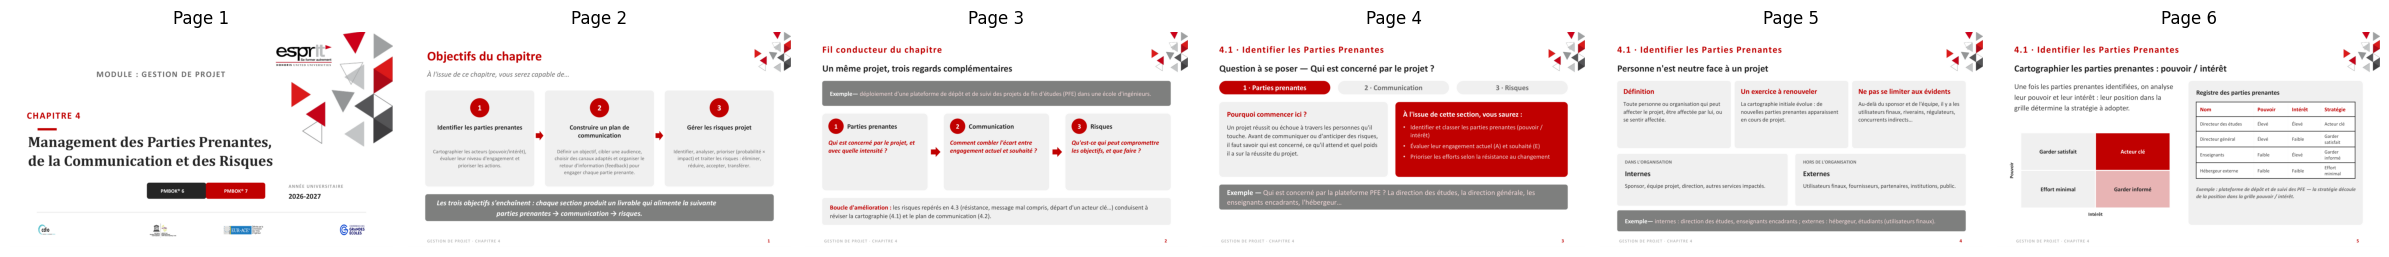

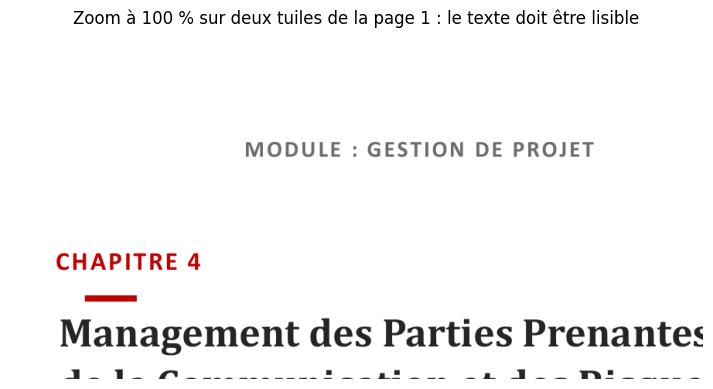

⏱️  Conversion des pages en images : 4.0 s | énergie GPU ≈ 0.07 Wh


{'etape': 'Conversion des pages en images',
 't_debut': 309.275999275,
 't_fin': 313.275410361,
 'duree_s': 3.999411086000009,
 'temps_cpu_s': 5.309999999999988,
 'gpu0_pic_pytorch_mo': 6976.65625,
 'gpu1_pic_pytorch_mo': 3672.099609375,
 'ram_pic_mo': 2249.05078125,
 'cpu_moyen_pct': 132.1375,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 8743.1875,
 'gpu0_puissance_moy_w': 31.5285,
 'gpu0_energie_wh': 0.03502650900693092,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 4645.1875,
 'gpu1_puissance_moy_w': 27.8455,
 'gpu1_energie_wh': 0.03093488927644813,
 'energie_gpu_wh': 0.06596139828337905}

In [8]:
PERF.debut("Conversion des pages en images")
TAILLE_TUILE_PX = 448   # Phi-4 découpe chaque image en tuiles de 448 x 448 px
DOSSIER_PAGES = os.path.join(DOSSIER_TRAVAIL, "pages")


def texte_de_la_page(page, max_caracteres=MAX_CARACTERES_TEXTE_PAGE):
    """Couche texte du PDF (vide pour un PDF scanné), nettoyée : NFC, sans caractères de contrôle ni puces de police."""
    try:
        brut = unicodedata.normalize("NFC", page.get_text("text", sort=True))
    except Exception:
        return ""
    lignes = []
    for ligne in brut.splitlines():
        ligne = "".join(c if unicodedata.category(c)[0] != "C" else " " for c in ligne)
        ligne = re.sub(r"\s+", " ", ligne).strip()
        if ligne:
            lignes.append(ligne)
    return "\n".join(lignes)[:max_caracteres]


def rendre_pages(doc, largeur_px, dossier):
    """Rend chaque page à la largeur demandée (proportions conservées), l'enregistre en PNG et extrait son texte."""
    os.makedirs(dossier, exist_ok=True)
    for ancien in os.listdir(dossier):
        if ancien.startswith("page_") and ancien.endswith(".png"):
            os.remove(os.path.join(dossier, ancien))
    pages = []
    for numero in NUMEROS_PAGES:
        page = doc[numero - 1]
        zoom = min(largeur_px / page.rect.width, 300 / 72)          # au plus 300 DPI
        pix = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False)
        image = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
        chemin = os.path.join(dossier, f"page_{numero:03d}.png")
        image.save(chemin)
        tuiles = (math.ceil(image.width / TAILLE_TUILE_PX), math.ceil(image.height / TAILLE_TUILE_PX))
        pages.append({"numero": numero, "image": image, "chemin": chemin, "largeur": image.width,
                      "hauteur": image.height, "dpi": 72 * zoom, "tuiles": tuiles,
                      "texte": texte_de_la_page(page) if AJOUTER_TEXTE_PDF else ""})
    return pages


def compter_tokens_images(pages):
    """Nombre exact de tokens visuels de chaque page, calculé par le processeur d'images de Phi-4 lui-même."""
    for p in pages:
        p["tokens"] = int(processor.image_processor(images=[p["image"]], return_tensors="pt")["num_img_tokens"][0])
    return pages


PAGES = compter_tokens_images(rendre_pages(DOC_PDF, LARGEUR_PAGE_PX, DOSSIER_PAGES))
PAGES_PAR_NUMERO = {p["numero"]: p for p in PAGES}

assert len(PAGES) == N_PAGES and [p["numero"] for p in PAGES] == NUMEROS_PAGES, "Pages manquantes ou dans le désordre"
TOKENS_IMAGES_TOTAL = sum(p["tokens"] for p in PAGES)
for p in PAGES:
    print(f"   Page {p['numero']} → {os.path.basename(p['chemin'])} : {p['largeur']} × {p['hauteur']} px "
          f"(≈ {p['dpi']:.0f} DPI) → {p['tuiles'][0]} × {p['tuiles'][1]} tuiles + vue d'ensemble = {p['tokens']} tokens"
          + (f" + {len(p['texte'])} caractères de texte" if AJOUTER_TEXTE_PDF else ""))
print(f"✅ {len(PAGES)} images dans l'ordre du PDF — {TOKENS_IMAGES_TOTAL} tokens visuels si on les envoyait toutes ; "
      f"chaque vérification n'en reçoit que {PAGES_PAR_AFFIRMATION} (≈ {PAGES_PAR_AFFIRMATION * PAGES[0]['tokens']} tokens)")
if AJOUTER_TEXTE_PDF:
    sans_texte = [p["numero"] for p in PAGES if not p["texte"]]
    if sans_texte:
        print(f"ℹ️  Pas de texte extractible pour les pages {sans_texte} (PDF scanné ?) : le modèle lira seulement l'image.")

# --- Aperçu : miniatures + zoom à 100 % pour contrôler la lisibilité des tableaux ---
n_apercu = min(len(PAGES), 6)
fig, axes = plt.subplots(1, n_apercu, figsize=(4 * n_apercu, 5.5))
for ax, p in zip(np.atleast_1d(axes), PAGES[:n_apercu]):
    ax.imshow(p["image"]); ax.set_title(f"Page {p['numero']}"); ax.axis("off")
plt.tight_layout(); plt.show()
p0 = PAGES[0]["image"]
plt.figure(figsize=(9, 4.5))
plt.imshow(p0.crop((0, 0, min(p0.width, TAILLE_TUILE_PX * 2), min(p0.height, TAILLE_TUILE_PX))))
plt.title(f"Zoom à 100 % sur deux tuiles de la page {PAGES[0]['numero']} : le texte doit être lisible")
plt.axis("off"); plt.show()
PERF.fin()

## 9. Importation et préparation de l'audio

In [9]:
PERF.debut("Préparation de l'audio")
FREQ_MODELE = 16000            # fréquence attendue par l'encodeur audio de Phi-4
DUREE_CONSEILLEE_MAX_S = 40     # Microsoft conseille au plus 40 s d'audio en usage général (jusqu'à 30 min pour un résumé)
EXTENSIONS_AUDIO = (".wav", ".mp3")
EXTENSIONS_AUDIO_TOLEREES = (".flac", ".ogg", ".m4a", ".aac", ".opus", ".webm")   # lues si possible (non garanti)
DOSSIER_AUDIO = os.path.join(DOSSIER_TRAVAIL, "audio")
os.makedirs(DOSSIER_AUDIO, exist_ok=True)


def lire_audio(chemin):
    """Lit un fichier audio en float32 de forme (échantillons, canaux), sans le modifier."""
    try:
        info = sf.info(chemin)
        signal, freq = sf.read(chemin, dtype="float32", always_2d=True)
        return signal, freq, f"soundfile (libsndfile {sf.__libsndfile_version__}), {info.format} / {info.subtype}"
    except Exception as e:
        y, freq = librosa.load(chemin, sr=None, mono=False)   # secours : décodage via audioread / ffmpeg
        signal = np.atleast_2d(y).T.astype(np.float32)
        return signal, int(freq), f"librosa (secours après échec de soundfile : {type(e).__name__})"


def formater_duree(secondes):
    return f"{int(secondes // 60)} min {secondes % 60:04.1f} s"


# --- 9.1 Localisation de l'audio (fourni via CHEMIN_AUDIO, ou cherché dans /kaggle/input) ---
UTILISE_DEMO_AUDIO = False   # conservé pour la traçabilité (toujours False : pas de mode démonstration)
if CHEMIN_AUDIO is None:
    audios_trouves = fichiers_presents(DOSSIER_ENTREES, EXTENSIONS_AUDIO)
    if not audios_trouves:
        audios_trouves = fichiers_presents(DOSSIER_ENTREES, EXTENSIONS_AUDIO_TOLEREES)
        if audios_trouves:
            print(f"⚠️  Aucun WAV/MP3, mais un autre format audio a été trouvé : {audios_trouves[0]} "
                  "(lecture tentée ; en cas d'échec, convertissez-le en WAV ou MP3).")
    if not audios_trouves:
        raise FileNotFoundError(
            f"❌ Aucun fichier WAV/MP3 trouvé dans {DOSSIER_ENTREES}. Renseignez CHEMIN_AUDIO ou ajoutez-le via Add Input → Upload.")
    CHEMIN_AUDIO = audios_trouves[0]
    if len(audios_trouves) > 1:
        print("⚠️  Plusieurs audios trouvés (le premier est utilisé ; sinon renseignez CHEMIN_AUDIO) :")
        for a in audios_trouves:
            print("     -", a)
if not os.path.isfile(CHEMIN_AUDIO):
    raise FileNotFoundError(f"❌ Fichier audio introuvable : {CHEMIN_AUDIO}")
extension = os.path.splitext(CHEMIN_AUDIO)[1].lower()
if extension not in EXTENSIONS_AUDIO:
    print(f"⚠️  Extension {extension} : seuls WAV et MP3 sont garantis ; tentative de lecture quand même.")

# --- 9.2 Conservation de l'original (copie binaire identique, jamais modifiée) ---
CHEMIN_AUDIO_ORIGINAL = os.path.join(DOSSIER_AUDIO, "original" + extension)
shutil.copyfile(CHEMIN_AUDIO, CHEMIN_AUDIO_ORIGINAL)
SHA256_AUDIO = empreinte_sha256(CHEMIN_AUDIO)
assert empreinte_sha256(CHEMIN_AUDIO_ORIGINAL) == SHA256_AUDIO, "La copie de l'original n'est pas identique"

# --- 9.3 Lecture et contrôles de qualité ---
signal, FREQ_ORIGINE, lecteur = lire_audio(CHEMIN_AUDIO)
DUREE_AUDIO_S = signal.shape[0] / FREQ_ORIGINE
if signal.shape[0] == 0 or DUREE_AUDIO_S < 3:
    raise ValueError(f"❌ Audio vide ou trop court ({DUREE_AUDIO_S:.1f} s) : au moins quelques secondes de parole sont nécessaires.")
crete = float(np.max(np.abs(signal)))
rms_db = 20 * np.log10(float(np.sqrt(np.mean(signal ** 2))) + 1e-12)
sature = float(np.mean(np.abs(signal) >= 0.999))
trames = signal.mean(axis=1)[: len(signal) // 400 * 400].reshape(-1, 400)   # trames de ~25 ms à 16 kHz
silence = float(np.mean(20 * np.log10(np.sqrt(np.mean(trames ** 2, axis=1)) + 1e-12) < -45)) if len(trames) else 0.0
print(f"✅ Audio : {CHEMIN_AUDIO}  (lu avec {lecteur})")
print(f"   Durée {formater_duree(DUREE_AUDIO_S)} | {FREQ_ORIGINE} Hz | {signal.shape[1]} canal(aux) | "
      f"crête {crete:.2f} | niveau moyen {rms_db:.1f} dBFS | saturation {100 * sature:.2f} % | silence ≈ {100 * silence:.0f} %")
print(f"   Original conservé à l'identique : {CHEMIN_AUDIO_ORIGINAL} (SHA-256 {SHA256_AUDIO[:16]}…)")
if crete < 0.05:
    print("⚠️  Niveau très faible : rapprochez le micro ou parlez plus fort pour une meilleure compréhension.")
if sature > 0.001:
    print("⚠️  Saturation détectée : baissez le gain du micro lors de l'enregistrement.")
if silence > 0.6:
    print("⚠️  L'enregistrement contient surtout du silence.")

# --- 9.4 Préparation au format Phi-4 : mono, 16 kHz, float32 (aucune transcription) ---
mono = signal.mean(axis=1) if signal.shape[1] > 1 else signal[:, 0]
if FREQ_ORIGINE != FREQ_MODELE:
    audio_16k = librosa.resample(mono, orig_sr=FREQ_ORIGINE, target_sr=FREQ_MODELE, res_type="soxr_hq")
else:
    audio_16k = mono.copy()
# Normalisation du volume (version envoyée au modèle seulement ; l'original reste intact)
GAIN_VOLUME_DB = 0.0
crete_16k = float(np.max(np.abs(audio_16k))) if len(audio_16k) else 0.0
if NORMALISER_VOLUME and crete_16k > 1e-4:
    GAIN_VOLUME_DB = 20 * np.log10(0.9 / crete_16k)
    audio_16k = audio_16k * np.float32(0.9 / crete_16k)
    print(f"🔊 Volume normalisé pour le modèle : gain de {GAIN_VOLUME_DB:+.1f} dB (crête {crete_16k:.2f} → 0.90)")
AUDIO_16K = np.ascontiguousarray(np.nan_to_num(audio_16k), dtype=np.float32)
del signal, mono, audio_16k
assert AUDIO_16K.ndim == 1 and AUDIO_16K.dtype == np.float32
assert abs(len(AUDIO_16K) / FREQ_MODELE - DUREE_AUDIO_S) < 0.01, "La durée a changé lors du rééchantillonnage"

# --- 9.5 Copie de contrôle et estimation des tokens audio ---
CHEMIN_AUDIO_16K = os.path.join(DOSSIER_AUDIO, "audio_16k_mono.wav")
sf.write(CHEMIN_AUDIO_16K, AUDIO_16K, FREQ_MODELE, subtype="FLOAT")
print(f"✅ Audio préparé : mono, {FREQ_MODELE} Hz, {len(AUDIO_16K)} échantillons ({formater_duree(len(AUDIO_16K) / FREQ_MODELE)}) ; "
      f"copie de contrôle : {CHEMIN_AUDIO_16K}")
print(f"   Tokens audio attendus ≈ {int(len(AUDIO_16K) / FREQ_MODELE * 12.5)} (12,5 tokens par seconde : 1 token = 80 ms)")
if DUREE_AUDIO_S > DUREE_CONSEILLEE_MAX_S:
    print(f"⚠️  Audio de plus de {DUREE_CONSEILLEE_MAX_S} s : Microsoft conseille au plus 40 s par requête. "
          "Découpez l'explication en morceaux plus courts si le modèle en oublie une partie.")
PERF.fin()

# --- Écoute ---
if os.path.getsize(CHEMIN_AUDIO) <= 8 * 2**20:
    print("▶️  Enregistrement original :"); display(LecteurAudio(filename=CHEMIN_AUDIO))
print("▶️  Version envoyée au modèle (16 kHz mono" + (", volume normalisé" if NORMALISER_VOLUME else "") + ") — 60 premières secondes :")
display(LecteurAudio(data=AUDIO_16K[: 60 * FREQ_MODELE], rate=FREQ_MODELE))

✅ Audio : /kaggle/input/datasets/eyajall/communication/Voix_261123_202702.mp3  (lu avec soundfile (libsndfile 1.2.2), MP3 / MPEG_LAYER_III)
   Durée 0 min 15.8 s | 48000 Hz | 1 canal(aux) | crête 0.26 | niveau moyen -28.9 dBFS | saturation 0.00 % | silence ≈ 49 %
   Original conservé à l'identique : /kaggle/working/analyse_phi4/audio/original.mp3 (SHA-256 30212b5555f384de…)
🔊 Volume normalisé pour le modèle : gain de +10.7 dB (crête 0.26 → 0.90)
✅ Audio préparé : mono, 16000 Hz, 252246 échantillons (0 min 15.8 s) ; copie de contrôle : /kaggle/working/analyse_phi4/audio/audio_16k_mono.wav
   Tokens audio attendus ≈ 197 (12,5 tokens par seconde : 1 token = 80 ms)
⏱️  Préparation de l'audio : 15.3 s | énergie GPU ≈ 0.25 Wh
▶️  Enregistrement original :


▶️  Version envoyée au modèle (16 kHz mono, volume normalisé) — 60 premières secondes :


**generation reponse**

In [10]:
BALISE_IMAGE, BALISE_AUDIO = processor.image_token, processor.audio_token   # « <|image|> » et « <|audio|> »


class DetecteurInstabilite(LogitsProcessor):
    """Interrompt la génération dès que des valeurs NaN/inf apparaissent (débordement numérique en FP16)."""
    def __call__(self, input_ids, scores):
        if not torch.isfinite(scores).all():
            raise FloatingPointError("valeurs NaN/inf dans les logits")
        return scores


class StreamerChrono(TextStreamer):
    """Affiche la réponse en direct ET note l'instant où le premier token est écrit (fin de la lecture de l'entrée)."""
    def __init__(self, tokenizer, afficher=True):
        super().__init__(tokenizer, skip_prompt=True, skip_special_tokens=True)
        self.afficher, self.t_premier_token = afficher, None

    def put(self, value):
        if not self.next_tokens_are_prompt and self.t_premier_token is None:
            self.t_premier_token = time.perf_counter()
        super().put(value)

    def on_finalized_text(self, text, stream_end=False):
        if self.afficher:
            super().on_finalized_text(text, stream_end)


def preparer_entrees(texte, images=None, audios=None):
    """Le processeur de Phi-4 remplace chaque balise par le bon nombre de tokens et calcule les tenseurs
    (tuiles des images, spectrogramme de l'audio)."""
    options = {}
    if images:
        options["images"] = images
    if audios:
        options.update(audio=audios, sampling_rate=FREQ_MODELE)
    return processor(text=texte, return_tensors="pt", **options)


PASSAGE_FP32, TENTATIVES = False, []


def generer(nom, texte, images=None, audios=None, adaptateur=ADAPTATEUR_VERIFICATION, max_nouveaux_tokens=400,
            prefixe="", en_direct=AFFICHER_EN_DIRECT):
    """UN appel au modèle, mesuré (temps, tokens, mémoire, énergie).
    `texte` se termine par « <|assistant|> » + `prefixe` : le préfixe impose le début de la réponse, le modèle écrit la suite
    (cela l'empêche de recopier le modèle de réponse de la consigne)."""
    global PASSAGE_FP32, DTYPE
    entrees = preparer_entrees(texte, images, audios)
    ids = entrees["input_ids"][0].tolist()
    n_image, n_audio = ids.count(ID_IMAGE), ids.count(ID_AUDIO)
    # --- vérifications : chaque image et l'audio sont bien dans la séquence, sans troncature ---
    if images:
        assert entrees["image_pixel_values"].shape[0] == len(images) and n_image > 0, "Images absentes de la séquence"
    if audios:
        assert n_audio == int(entrees["audio_embed_sizes"].sum()) > 0, "Audio absent de la séquence"
        duree_vue = entrees["audio_input_features"].shape[1] / 100           # 100 trames par seconde
        assert abs(duree_vue - len(audios[0]) / FREQ_MODELE) < 0.1, "L'audio a été tronqué !"
    if len(ids) + max_nouveaux_tokens > CONFIG_TEXTE.max_position_embeddings:
        raise ValueError("❌ Requête trop longue pour le contexte du modèle.")
    entrees = entrees.to(PERIPHERIQUE_ENTREE)      # le modèle convertit lui-même images et audio dans sa précision
    model.set_adapter(adaptateur)
    parametres = dict(max_new_tokens=max_nouveaux_tokens, do_sample=ECHANTILLONNAGE, repetition_penalty=1.05,
                      eos_token_id=[ID_END, ID_ENDOFTEXT], pad_token_id=ID_ENDOFTEXT,
                      logits_processor=LogitsProcessorList([DetecteurInstabilite()]))
    if ECHANTILLONNAGE:
        parametres.update(temperature=0.7, top_p=0.9)
    while True:
        streamer = StreamerChrono(processor.tokenizer, afficher=en_direct)
        if en_direct and prefixe:
            print(prefixe, end="", flush=True)
        mesure = PERF.debut_inference(nom, adaptateur=adaptateur, precision=str(DTYPE).replace("torch.", ""),
                                      tokens_entree=len(ids), tokens_image=n_image, tokens_audio=n_audio,
                                      tokens_texte=len(ids) - n_image - n_audio)
        try:
            with torch.inference_mode():
                sortie = model.generate(**entrees, **parametres, streamer=streamer)
            break
        except FloatingPointError as e:
            TENTATIVES.append(f"{nom} — {type(e).__name__}: {e}")
            liberer_memoire()
            if PASSAGE_FP32:
                raise
            # Phi-4 a été entraîné en BF16 : si le FP16 déborde, on passe tout le modèle en FP32 (≈ 21 Gio sur 2 T4)
            print("\n⚠️  Instabilité numérique en FP16 → passage du modèle en FP32 (plus lent) et nouvelle tentative.")
            model.float()
            DTYPE, PASSAGE_FP32 = torch.float32, True
            liberer_memoire()
    nouveaux = sortie[0, len(ids):]
    PERF.fin_inference(mesure, streamer.t_premier_token, len(nouveaux))
    mesure["limite_atteinte"] = len(nouveaux) >= max_nouveaux_tokens
    if en_direct:
        print()
    reponse = prefixe + processor.tokenizer.decode(nouveaux, skip_special_tokens=True, clean_up_tokenization_spaces=False)
    return reponse.strip(), mesure


def resume_inference(m):
    return (f"   ⏱️  {m['duree_s']:.1f} s (lecture de l'entrée {m['ttft_s']:.1f} s + écriture "
            f"{m['tokens_sortie']} tokens à {m['vitesse_ecriture_tok_s']:.1f} tokens/s) | entrée {m['tokens_entree']} tokens "
            f"(image {m['tokens_image']}, audio {m['tokens_audio']}, texte {m['tokens_texte']}) | "
            f"mémoire PyTorch pic : " + " / ".join(f"GPU{i} {m.get(f'gpu{i}_pic_pytorch_mo', 0) / 1024:.1f} Gio"
                                                  for i in range(PERF.n_gpu))
            + f" | énergie ≈ {m['energie_gpu_wh']:.2f} Wh")


print(f"✅ Fonctions de génération prêtes — balises : {BALISE_IMAGE} {BALISE_AUDIO} | "
      f"adaptateurs : écoute « {ADAPTATEUR_ECOUTE} », vérification « {ADAPTATEUR_VERIFICATION} »")

✅ Fonctions de génération prêtes — balises : <|image|> <|audio|> | adaptateurs : écoute « speech », vérification « vision »


## 11. Étape 1 — Écoute de l'explication orale

- 

In [11]:
PERF.debut("Étape 1 — Écoute de l'audio")
DOSSIER_RESULTATS = os.path.join(DOSSIER_TRAVAIL, "resultats")
os.makedirs(DOSSIER_RESULTATS, exist_ok=True)

# Consigne d'écoute : Microsoft a entraîné le mode « speech » avec des consignes en anglais (« Transcribe the audio clip
# into text. ») ; on précise que la personne parle français et qu'il ne faut ni traduire ni corriger.
CONSIGNES_ECOUTE = [
    "Transcribe the audio clip into text. The speaker speaks French: write exactly what is said, in French, word for "
    "word, with punctuation. Do not translate, do not correct mistakes, do not summarize.",
    "Écris en français, mot pour mot et avec la ponctuation, tout ce que dit la personne dans cet enregistrement. "
    "Ne traduis pas, ne corrige pas ses erreurs, ne résume pas.",          # seconde tentative si la 1re sort en anglais
]
MOTS_FRANCAIS = {"le", "la", "les", "de", "des", "du", "est", "et", "un", "une", "que", "qui", "dans", "pour", "on",
                 "ce", "c'est", "il", "elle", "sont", "pas", "avec", "sur", "au", "aux", "en"}
MOTS_ANGLAIS = {"the", "is", "and", "of", "to", "in", "that", "it", "for", "this", "are", "with", "on", "be", "we"}


def langue_probable(texte):
    mots = re.findall(r"[a-zà-ÿ']+", (texte or "").lower())
    fr, en = sum(m in MOTS_FRANCAIS for m in mots), sum(m in MOTS_ANGLAIS for m in mots)
    return "anglais" if en > fr else "français"


def decouper_en_affirmations(texte, min_mots=4, max_mots=40):
    """Découpe ce que le modèle a entendu en affirmations (une phrase = une affirmation).
    Les fragments très courts sont rattachés à la phrase précédente ; les phrases très longues sont coupées aux virgules."""
    texte = re.sub(r"\s+", " ", texte or "").strip()
    phrases = [p.strip() for p in re.split(r"(?<=[.!?;…])\s+", texte) if p.strip()]
    morceaux = []
    for phrase in phrases:
        if len(phrase.split()) <= max_mots:
            morceaux.append(phrase)
            continue
        courant = []
        for partie in re.split(r"(?<=,)\s+", phrase):
            courant.append(partie)
            if len(" ".join(courant).split()) >= max_mots // 2:
                morceaux.append(" ".join(courant))
                courant = []
        if courant:
            morceaux.append(" ".join(courant))
    fusion = []
    for m in morceaux:
        if fusion and len(m.split()) < min_mots:
            fusion[-1] += " " + m
        else:
            fusion.append(m)
    if len(fusion) > 1 and len(fusion[0].split()) < min_mots:
        fusion[1] = fusion[0] + " " + fusion[1]
        fusion.pop(0)
    return fusion


print(f"🎧 Phi-4 écoute l'enregistrement original ({formater_duree(DUREE_AUDIO_S)}) avec l'adaptateur "
      f"« {ADAPTATEUR_ECOUTE} » — audio seul, sans le cours :\n" + "─" * 72)
for k, consigne in enumerate(CONSIGNES_ECOUTE, start=1):
    TEXTE_ECOUTE = f"<|user|>{BALISE_AUDIO}{consigne}<|end|><|assistant|>"
    nom = "Écoute (audio → texte)" if k == 1 else f"Écoute — essai {k} (consigne en français)"
    ECOUTE_BRUTE, MESURE_ECOUTE = generer(nom, TEXTE_ECOUTE, audios=[AUDIO_16K],
                                          adaptateur=ADAPTATEUR_ECOUTE, max_nouveaux_tokens=MAX_TOKENS_ECOUTE)
    if ECOUTE_BRUTE and langue_probable(ECOUTE_BRUTE) == "français":
        break
    if k < len(CONSIGNES_ECOUTE):
        print("⚠️  Réponse vide ou en anglais (le modèle a peut-être traduit) → nouvelle écoute avec une consigne en français.\n")
print("─" * 72)
print(resume_inference(MESURE_ECOUTE))
print(f"   Facteur temps réel : {MESURE_ECOUTE['duree_s'] / DUREE_AUDIO_S:.2f} "
      f"({MESURE_ECOUTE['duree_s']:.1f} s de calcul pour {DUREE_AUDIO_S:.1f} s d'audio)")

if not ECOUTE_BRUTE.strip():
    raise RuntimeError("❌ Le modèle n'a rien entendu : vérifiez l'audio (volume, durée, format) dans la section 9.")
if langue_probable(ECOUTE_BRUTE) != "français":
    print("⚠️  L'écoute semble être en anglais : la comparaison avec un cours en français sera moins fiable.")
if MESURE_ECOUTE["limite_atteinte"]:
    print("⚠️  Limite de longueur atteinte pendant l'écoute : augmentez MAX_TOKENS_ECOUTE.")

AFFIRMATIONS = [{"id": f"A{k}", "texte": t} for k, t in enumerate(decouper_en_affirmations(ECOUTE_BRUTE), start=1)]
assert AFFIRMATIONS, "Aucune affirmation n'a pu être extraite de l'écoute"
print(f"\n✅ {len(AFFIRMATIONS)} affirmation(s) de l'étudiant, telles que Phi-4 les a entendues :")
for a in AFFIRMATIONS:
    print(f"   {a['id']:4s} « {a['texte']} »")
with open(os.path.join(DOSSIER_RESULTATS, "ecoute_modele.md"), "w", encoding="utf-8") as f:
    f.write(ECOUTE_BRUTE + "\n\n" + "\n".join(f"{a['id']} : {a['texte']}" for a in AFFIRMATIONS))
PERF.fin(affirmations=len(AFFIRMATIONS))

🎧 Phi-4 écoute l'enregistrement original (0 min 15.8 s) avec l'adaptateur « speech » — audio seul, sans le cours :
────────────────────────────────────────────────────────────────────────
Incertitude : c'est événement incertain, identifié à probabilité et impact estimable. Le risque : c'est ce qu'on ne peut pas prévoir avec précision.

────────────────────────────────────────────────────────────────────────
   ⏱️  8.1 s (lecture de l'entrée 5.7 s + écriture 35 tokens à 14.1 tokens/s) | entrée 242 tokens (image 0, audio 197, texte 45) | mémoire PyTorch pic : GPU0 6.9 Gio / GPU1 3.7 Gio | énergie ≈ 0.16 Wh
   Facteur temps réel : 0.51 (8.1 s de calcul pour 15.8 s d'audio)

✅ 2 affirmation(s) de l'étudiant, telles que Phi-4 les a entendues :
   A1   « Incertitude : c'est événement incertain, identifié à probabilité et impact estimable. »
   A2   « Le risque : c'est ce qu'on ne peut pas prévoir avec précision. »
⏱️  Étape 1 — Écoute de l'audio : 8.2 s | énergie GPU ≈ 0.17 Wh


{'etape': "Étape 1 — Écoute de l'audio",
 't_debut': 328.635391299,
 't_fin': 336.873940824,
 'duree_s': 8.238549524999996,
 'temps_cpu_s': 4.439999999999998,
 'gpu0_pic_pytorch_mo': 7026.876953125,
 'gpu1_pic_pytorch_mo': 3797.64892578125,
 'ram_pic_mo': 3389.98046875,
 'cpu_moyen_pct': 59.473684210526315,
 'gpu0_util_moy_pct': 15.526315789473685,
 'gpu0_util_max_pct': 48.0,
 'gpu0_occupe_pic_mo': 8777.1875,
 'gpu0_puissance_moy_w': 43.50478947368421,
 'gpu0_energie_wh': 0.09956010073712387,
 'gpu1_util_moy_pct': 6.2105263157894735,
 'gpu1_util_max_pct': 17.0,
 'gpu1_occupe_pic_mo': 4665.1875,
 'gpu1_puissance_moy_w': 29.401894736842102,
 'gpu1_energie_wh': 0.06728582386619733,
 'energie_gpu_wh': 0.1668459246033212,
 'affirmations': 2}

## 12. Choix des pages du cours pour chaque affirmation

Les 31 pages sont candidates. Pour chaque affirmation, le notebook mesure la proximité entre ses mots et le texte de chaque
page (TF-IDF + similarité cosinus) et garde les `PAGES_PAR_AFFIRMATION` pages les plus proches. Les mots présents sur
presque toutes les pages (titre du chapitre…) comptent peu. Le modèle voit ainsi ≈ 3 200 tokens d'images par vérification
au lieu de 49 000.

In [12]:
PERF.debut("Sélection des pages du cours")


def sans_accents(texte):
    return "".join(c for c in unicodedata.normalize("NFKD", texte or "") if not unicodedata.combining(c))


MOTS_VIDES = set(sans_accents("""
le la les l un une des du de d et ou en au aux a à ce ces cet cette c ça cela ceci est sont être été il elle ils elles on
nous vous je j tu se s sa son ses leur leurs lui que qu qui quoi dont où ne n pas plus moins pour par sur sous dans avec
sans entre comme mais donc car si y me m te t aussi très tout tous toute toutes alors bien fait faire peut peuvent doit
avoir ont a va voilà euh ben bah hein ensuite après avant puis enfin quand chaque même autre autres ici là deux trois
""").split())


def racines(texte):
    """Mots utiles d'un texte, sans accents, réduits à leurs 6 premières lettres (« probabilité » et « probable » → « probab »)."""
    mots = re.findall(r"[a-z0-9]+", sans_accents((texte or "").lower()))
    return [m[:6] for m in mots if len(m) > 2 and m not in MOTS_VIDES]


# --- Représentation TF-IDF de chaque page (les mots présents sur toutes les pages, comme le titre du chapitre, comptent peu) ---
COMPTES_PAGES = {p["numero"]: Counter(racines(p["texte"])) for p in PAGES}
N_DOCS = len(COMPTES_PAGES)
FREQ_DOC = Counter(r for c in COMPTES_PAGES.values() for r in c)
IDF = {r: math.log((1 + N_DOCS) / (1 + n)) + 1 for r, n in FREQ_DOC.items()}


def vecteur(compte):
    v = {r: (1 + math.log(n)) * IDF.get(r, math.log(1 + N_DOCS) + 1) for r, n in compte.items()}
    norme = math.sqrt(sum(x * x for x in v.values())) or 1.0
    return {r: x / norme for r, x in v.items()}


VECTEURS_PAGES = {n: vecteur(c) for n, c in COMPTES_PAGES.items()}
PDF_SANS_TEXTE = sum(len(c) for c in COMPTES_PAGES.values()) == 0


def pages_proches(texte, k=PAGES_PAR_AFFIRMATION):
    """Les k pages dont le texte est le plus proche de l'affirmation (similarité cosinus TF-IDF)."""
    if PDF_SANS_TEXTE:
        return [(0.0, n) for n in NUMEROS_PAGES[:k]]
    va = vecteur(Counter(racines(texte)))
    scores = sorted(((sum(x * vp.get(r, 0.0) for r, x in va.items()), n) for n, vp in VECTEURS_PAGES.items()),
                    key=lambda s: (-s[0], s[1]))
    return scores[:k]


if PDF_SANS_TEXTE:
    print("⚠️  Le PDF n'a pas de couche texte (scanné ?) : impossible de choisir les pages par le texte. Les "
          f"{PAGES_PAR_AFFIRMATION} premières pages de PAGES_A_ANALYSER sont utilisées : limitez PAGES_A_ANALYSER aux pages utiles.")
for a in AFFIRMATIONS:
    proches = pages_proches(a["texte"])
    a["pages"] = sorted(n for _, n in proches)                  # dans l'ordre du PDF
    a["scores_pages"] = {n: round(s, 3) for s, n in proches}
    a["lien_faible"] = (not PDF_SANS_TEXTE) and max(s for s, _ in proches) < 0.05

print(f"Pages montrées au modèle pour chaque affirmation (parmi {N_PAGES} pages candidates) :")
for a in AFFIRMATIONS:
    detail = ", ".join(f"p.{n} ({a['scores_pages'][n]:.2f})" for n in a["pages"])
    print(f"   {a['id']:4s} → {detail}" + ("   ⚠️ peu de mots en commun avec le cours" if a["lien_faible"] else ""))
PAGES_UTILISEES = sorted({n for a in AFFIRMATIONS for n in a["pages"]})
print(f"✅ {len(PAGES_UTILISEES)} page(s) différente(s) utilisée(s) : {PAGES_UTILISEES}")
PERF.fin()

Pages montrées au modèle pour chaque affirmation (parmi 31 pages candidates) :
   A1   → p.16 (0.20), p.17 (0.36)
   A2   → p.17 (0.25), p.20 (0.15)
✅ 3 page(s) différente(s) utilisée(s) : [16, 17, 20]
⏱️  Sélection des pages du cours : 0.0 s | énergie GPU ≈ 0.00 Wh


{'etape': 'Sélection des pages du cours',
 't_debut': 336.900170829,
 't_fin': 336.917340932,
 'duree_s': 0.017170103000012205,
 'temps_cpu_s': 0.009999999999990905,
 'gpu0_pic_pytorch_mo': 6976.65625,
 'gpu1_pic_pytorch_mo': 3673.10009765625,
 'ram_pic_mo': 3390.125,
 'cpu_moyen_pct': 117.4,
 'gpu0_util_moy_pct': 46.0,
 'gpu0_util_max_pct': 46.0,
 'gpu0_occupe_pic_mo': 8777.1875,
 'gpu0_puissance_moy_w': 42.435,
 'gpu0_energie_wh': 0.0002023925891126439,
 'gpu1_util_moy_pct': 17.0,
 'gpu1_util_max_pct': 17.0,
 'gpu1_occupe_pic_mo': 4665.1875,
 'gpu1_puissance_moy_w': 28.116,
 'gpu1_energie_wh': 0.00013409850443009533,
 'energie_gpu_wh': 0.0003364910935427392}

## 13. Étape 2 — Vérification de chaque affirmation

Un appel par affirmation, adaptateur « vision » : les pages choisies (image + texte extrait), la phrase précédente comme
contexte, puis la phrase à vérifier.
- Consigne système + **un exemple guidé** sur un autre sujet (le cycle de l'eau) qui montre le format et un verdict INCORRECT.
- La réponse est **commencée par le notebook** (« Page : ») : le modèle écrit la suite et ne peut plus recopier le gabarit.
- Secours : mémoire insuffisante → pages à 896 px, puis une seule page ; débordement FP16 → passage en FP32.

In [13]:
PERF.debut("Étape 2 — Vérification des affirmations")

CONSIGNE_SYSTEME = """Tu es un enseignant expert et rigoureux. On te montre des pages d'un support de cours, puis UNE phrase dite par un étudiant pendant son explication orale. Tu vérifies si cette phrase est conforme au cours.
Ne suppose pas que l'étudiant a raison : compare les définitions, les exemples, les chiffres, les cases des tableaux et surtout les inversions entre deux notions (attribuer à une notion ce que le cours dit d'une autre), qui sont les erreurs les plus fréquentes.
Verdicts possibles :
- CORRECT : la phrase est conforme au cours ;
- INCORRECT : elle contredit le cours (définition fausse, notions inversées, exemple mal attribué, chiffre ou formule faux, raisonnement incohérent) ;
- NON VÉRIFIABLE : les pages montrées ne parlent pas de cette notion, ou la phrase n'affirme rien (introduction, hésitation).
Une notion que l'étudiant n'a pas mentionnée n'est jamais une erreur. N'invente aucun contenu.
Réponds en français avec exactement 5 lignes, qui commencent par « Page : », « Le cours dit : », « Verdict : », « Pourquoi : » et « Correction : ». Après « Page : », écris le numéro de la page. Après « Le cours dit : », recopie la phrase du cours sur cette notion. Après « Verdict : », écris un seul des trois verdicts. Si le verdict n'est pas INCORRECT, écris « — » après « Pourquoi : » et après « Correction : »."""

# Exemple guidé (sur un tout autre sujet) : montre le format attendu ET qu'une phrase peut être INCORRECTE
EXEMPLE_QUESTION = ("Page 3 du cours : « L'évaporation transforme l'eau liquide en vapeur d'eau. La condensation transforme "
                    "la vapeur d'eau en gouttelettes. »\n\nPhrase dite par l'étudiant : « La condensation, c'est quand "
                    "l'eau liquide se transforme en vapeur. »\nVérifie cette phrase.")
EXEMPLE_REPONSE = ("Page : 3\nLe cours dit : « La condensation transforme la vapeur d'eau en gouttelettes. »\n"
                   "Verdict : INCORRECT\nPourquoi : l'étudiant donne à la condensation la définition de l'évaporation "
                   "(notions inversées).\nCorrection : la condensation transforme la vapeur d'eau en gouttelettes ; c'est "
                   "l'évaporation qui transforme l'eau liquide en vapeur.")
PREFIXE_VERIFICATION = "Page :"
CACHE_PAGES = {}


def page_a_la_largeur(numero, largeur):
    """La page déjà rendue, ou une version plus petite (secours en cas de mémoire GPU insuffisante)."""
    if largeur == LARGEUR_PAGE_PX:
        return PAGES_PAR_NUMERO[numero]
    if (numero, largeur) not in CACHE_PAGES:
        page = DOC_PDF[numero - 1]
        zoom = min(largeur / page.rect.width, 300 / 72)
        pix = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False)
        image = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
        CACHE_PAGES[(numero, largeur)] = {**PAGES_PAR_NUMERO[numero], "image": image,
                                          "largeur": image.width, "hauteur": image.height}
    return CACHE_PAGES[(numero, largeur)]


def construire_requete_verification(affirmation, pages, precedente=None):
    """Système + exemple guidé + UN message : pages (image + texte) [+ audio] + la phrase à vérifier."""
    morceaux = [f"Pages du support de cours ({len(pages)}) :\n"]
    for p in pages:
        morceaux.append(f"\n--- Page {p['numero']}/{N_PAGES_PDF} ---\n{BALISE_IMAGE}\n")
        if AJOUTER_TEXTE_PDF and p.get("texte"):
            morceaux.append(f"Texte de la page {p['numero']} (extrait du PDF) :\n{p['texte']}\n")
    if AUDIO_DANS_VERIFICATION:
        morceaux.append(f"\nEnregistrement original de l'explication de l'étudiant :\n{BALISE_AUDIO}\n")
    if precedente:
        morceaux.append(f"\nPhrase précédente de l'étudiant (contexte seulement, ne pas la vérifier) : « {precedente} »")
    morceaux.append(f"\nPhrase dite par l'étudiant : « {affirmation} »\nVérifie cette phrase.")
    return (f"<|system|>{CONSIGNE_SYSTEME}<|end|>"
            f"<|user|>{EXEMPLE_QUESTION}<|end|><|assistant|>{EXEMPLE_REPONSE}<|end|>"
            f"<|user|>{''.join(morceaux)}<|end|><|assistant|>{PREFIXE_VERIFICATION}")


VERIFICATIONS = []
for k, a in enumerate(AFFIRMATIONS):
    precedente = AFFIRMATIONS[k - 1]["texte"] if k > 0 else None
    largeur, numeros = LARGEUR_PAGE_PX, list(a["pages"])
    print(f"\n🔎 {a['id']} « {a['texte']} »\n   pages montrées : {numeros}\n" + "─" * 72)
    while True:
        try:
            pages = [page_a_la_largeur(n, largeur) for n in numeros]
            texte = construire_requete_verification(a["texte"], pages, precedente)
            assert texte.count(BALISE_IMAGE) == len(pages), "Une balise image par page"
            reponse, mesure = generer(f"Vérification {a['id']}", texte, images=[p["image"] for p in pages],
                                      audios=[AUDIO_16K] if AUDIO_DANS_VERIFICATION else None,
                                      adaptateur=ADAPTATEUR_VERIFICATION, max_nouveaux_tokens=MAX_TOKENS_VERIFICATION,
                                      prefixe=PREFIXE_VERIFICATION)
            break
        except Exception as e:
            if not est_erreur_memoire(e):
                raise
            TENTATIVES.append(f"Vérification {a['id']} — mémoire GPU insuffisante ({largeur} px, {len(numeros)} page(s))")
            liberer_memoire()
            if largeur > 896:
                largeur = 896
                print(f"\n⚠️  Mémoire GPU insuffisante → pages rendues à {largeur} px et nouvelle tentative.")
            elif len(numeros) > 1:
                numeros = numeros[:1]
                print(f"\n⚠️  Mémoire GPU insuffisante → une seule page ({numeros[0]}) et nouvelle tentative.")
            else:
                raise RuntimeError("❌ Mémoire GPU insuffisante même avec une seule page.") from e
    print("─" * 72 + "\n" + resume_inference(mesure))
    if mesure["limite_atteinte"]:
        print("   ⚠️ limite de longueur atteinte : augmentez MAX_TOKENS_VERIFICATION")
    VERIFICATIONS.append({**a, "pages_envoyees": numeros, "largeur_px": largeur, "reponse": reponse,
                          "limite_atteinte": mesure["limite_atteinte"]})

with open(os.path.join(DOSSIER_RESULTATS, "reponses_brutes_verification.md"), "w", encoding="utf-8") as f:
    for v in VERIFICATIONS:
        f.write(f"## {v['id']} « {v['texte']} » (pages {v['pages_envoyees']})\n\n{v['reponse']}\n\n")
PERF.fin(affirmations=len(VERIFICATIONS))


🔎 A1 « Incertitude : c'est événement incertain, identifié à probabilité et impact estimable. »
   pages montrées : [16, 17]
────────────────────────────────────────────────────────────────────────
Page : 17
Le cours dit : « Incerte : Ce qu'on ne peut pas prévoir avec précision »
Verdict : INCORRECT
Pourquoi : l'étudiant décrit incorrectement l'incertitude comme un événement incertain identifié à probabilité et impact estimable, alors que cela devrait être décrit comme quelque chose que l'on ne peut pas prévoir avec précision.
Correction : l'incertitude est ce qu'on ne peut pas prévoir avec précision.

────────────────────────────────────────────────────────────────────────
   ⏱️  9.4 s (lecture de l'entrée 3.2 s + écriture 91 tokens à 14.4 tokens/s) | entrée 4215 tokens (image 3192, audio 0, texte 1023) | mémoire PyTorch pic : GPU0 7.7 Gio / GPU1 4.2 Gio | énergie ≈ 0.27 Wh

🔎 A2 « Le risque : c'est ce qu'on ne peut pas prévoir avec précision. »
   pages montrées : [17, 20]
──────────

{'etape': 'Étape 2 — Vérification des affirmations',
 't_debut': 336.943338751,
 't_fin': 355.380398833,
 'duree_s': 18.437060082000016,
 'temps_cpu_s': 18.99000000000001,
 'gpu0_pic_pytorch_mo': 7874.95849609375,
 'gpu1_pic_pytorch_mo': 4300.34423828125,
 'ram_pic_mo': 3442.51953125,
 'cpu_moyen_pct': 106.96097560975609,
 'gpu0_util_moy_pct': 55.1219512195122,
 'gpu0_util_max_pct': 100.0,
 'gpu0_occupe_pic_mo': 8777.1875,
 'gpu0_puissance_moy_w': 60.79156097560976,
 'gpu0_energie_wh': 0.3113382394960791,
 'gpu1_util_moy_pct': 26.70731707317073,
 'gpu1_util_max_pct': 100.0,
 'gpu1_occupe_pic_mo': 4945.1875,
 'gpu1_puissance_moy_w': 39.13751219512196,
 'gpu1_energie_wh': 0.2004390732781866,
 'energie_gpu_wh': 0.5117773127742657,
 'affirmations': 2}

In [14]:
PERF.debut("Extraction des erreurs")
VERDICTS_VALIDES = ("CORRECT", "INCORRECT", "NON VÉRIFIABLE")


def nettoyer(valeur):
    """Retire le gras Markdown, les guillemets et les valeurs vides (« — », « … ») autour d'une valeur."""
    v = (valeur or "").strip().strip("*").strip()
    v = v.strip("«»\"“”").strip()
    return "" if v.lower() in ("", "-", "—", "–", "…", "...", "n/a", "aucun", "aucune", "néant") else v


RE_CHAMP = re.compile(r"^\s*(?:[-*•]\s*)?\**\s*([^:：*\n]{2,40}?)\s*\**\s*[:：]\s*\**\s*(.*?)\s*$")


def type_de_champ(etiquette):
    e = sans_accents(etiquette).lower().strip()
    if e.startswith("page"):
        return "page"
    if "verdict" in e:
        return "verdict"
    if e.startswith("correction"):
        return "correction"
    if "cours" in e:
        return "cours"
    if e.startswith(("pourquoi", "explication", "raison", "justification")):
        return "pourquoi"
    return None


def classer_verdict(verdict):
    t = sans_accents(verdict).upper()
    if "PARTIELLEMENT" in t:      # « partiellement correct » = une partie est fausse
        return "INCORRECT"
    trouves = set()
    if re.search(r"\bINCORRECT|\bFAUX\b|\bFAUSSE\b|\bERRONE|NON CONFORME|\bINEXACT", t):
        trouves.add("INCORRECT")
    if re.search(r"NON[ \-]VERIFIABLE|INVERIFIABLE|INAUDIBLE|PAS DANS LE COURS|HORS (DU )?COURS", t):
        trouves.add("NON VÉRIFIABLE")
    if re.search(r"\bCORRECTE?\b|\bJUSTE\b|(?<!NON )\bCONFORME\b|\bEXACTE?\b", t):
        trouves.add("CORRECT")
    if len(trouves) == 1:
        return trouves.pop()
    return "INCONNU"         # aucun verdict, ou plusieurs (le modèle a recopié « CORRECT, INCORRECT ou NON VÉRIFIABLE »)


def lire_verification(reponse):
    """Lit les 5 lignes « Page / Le cours dit / Verdict / Pourquoi / Correction » (s'arrête si un 2e bloc commence)."""
    champs, dernier = {}, None
    for ligne in (reponse or "").replace("\r\n", "\n").splitlines():
        if not ligne.strip():
            continue
        mc = RE_CHAMP.match(ligne)
        cle = type_de_champ(mc.group(1)) if mc else None
        if cle:
            if cle in champs:          # le modèle enchaîne sur un autre bloc : on garde le premier
                break
            champs[cle], dernier = mc.group(2), cle
        elif dernier:
            champs[dernier] += " " + ligne.strip().lstrip("-*• ").strip()
    return champs


def recopie_de_consigne(champs):
    """Le modèle a-t-il recopié la consigne au lieu de répondre ?"""
    texte = sans_accents(" ".join(champs.values())).lower()
    return any(m in texte for m in ("recopie la phrase", "numero de la page", "un seul des trois",
                                    "correct, incorrect ou", "« … »", "« ... »"))


ANALYSE = []
for v in VERIFICATIONS:
    c = lire_verification(v["reponse"])
    verdict = classer_verdict(c.get("verdict", ""))
    probleme = ""
    if not c:
        probleme = "réponse sans le format attendu"
    elif recopie_de_consigne(c):
        verdict, probleme = "INCONNU", "le modèle a recopié la consigne au lieu de répondre"
        c = {}
    elif verdict == "INCONNU":
        probleme = "verdict absent ou ambigu" + (" (réponse tronquée)" if v["limite_atteinte"] else "")
    page_citee = nettoyer(c.get("page"))
    numeros_cites = [int(n) for n in re.findall(r"\d+", page_citee)]
    ANALYSE.append({
        "id": v["id"], "affirmation": v["texte"], "pages_envoyees": v["pages_envoyees"],
        "page": ", ".join(str(n) for n in numeros_cites) or page_citee,
        "page_hors_selection": bool(numeros_cites) and not set(numeros_cites) & set(v["pages_envoyees"]),
        "cours": nettoyer(c.get("cours")), "verdict": verdict,
        "pourquoi": nettoyer(c.get("pourquoi")), "correction": nettoyer(c.get("correction")),
        "probleme": probleme,
    })

ERREURS = [a for a in ANALYSE if a["verdict"] == "INCORRECT"]
COMPTE_VERDICTS = Counter(a["verdict"] for a in ANALYSE)
SANS_VERDICT = [a for a in ANALYSE if a["verdict"] not in VERDICTS_VALIDES]
# « Aucune erreur » n'est conclu que si TOUTES les affirmations ont reçu un vrai verdict
ANALYSE_COMPLETE = bool(ANALYSE) and not SANS_VERDICT

ALERTES_ANALYSE = []
if SANS_VERDICT:
    ALERTES_ANALYSE.append(f"{len(SANS_VERDICT)} affirmation(s) sans verdict exploitable : "
                           + ", ".join(f"{a['id']} ({a['probleme']})" for a in SANS_VERDICT))
if ANALYSE and all(a["verdict"] == "NON VÉRIFIABLE" for a in ANALYSE):
    ALERTES_ANALYSE.append("aucune affirmation n'a pu être rattachée au cours : explication hors sujet, mauvaises pages "
                           "(PAGES_A_ANALYSER) ou audio mal compris (voir l'étape 1)")
hors = [a["id"] for a in ANALYSE if a["page_hors_selection"]]
if hors:
    ALERTES_ANALYSE.append(f"page citée en dehors des pages montrées pour {', '.join(hors)} (à vérifier)")
if any(a.get("lien_faible") for a in AFFIRMATIONS):
    ALERTES_ANALYSE.append("certaines affirmations ont peu de mots en commun avec le cours : vérifiez l'écoute (étape 1)")

print(f"Affirmations : {len(ANALYSE)} | " + " | ".join(f"{v} : {n}" for v, n in COMPTE_VERDICTS.most_common()))
for a in ANALYSE:
    print(f"   {a['id']:4s} [{a['verdict']:14s}] p.{a['page'] or '?':>3s}  « {a['affirmation'][:90]} »"
          + (f"  ⚠️ {a['probleme']}" if a["probleme"] else ""))
for alerte in ALERTES_ANALYSE:
    print("⚠️ ", alerte)
if ERREURS:
    print(f"\n❌ {len(ERREURS)} erreur(s) détectée(s)")
elif ANALYSE_COMPLETE:
    print(f"\n✅ Aucune erreur détectée : les {len(ANALYSE)} affirmation(s) ont toutes reçu un verdict")
else:
    print("\n⚠️  Analyse incomplète : impossible de conclure qu'il n'y a pas d'erreur (voir les alertes)")
with open(os.path.join(DOSSIER_RESULTATS, "analyse.json"), "w", encoding="utf-8") as f:
    json.dump(ANALYSE, f, ensure_ascii=False, indent=2)
PERF.fin(afficher=False)

Affirmations : 2 | INCORRECT : 2
   A1   [INCORRECT     ] p. 17  « Incertitude : c'est événement incertain, identifié à probabilité et impact estimable. »
   A2   [INCORRECT     ] p. 20  « Le risque : c'est ce qu'on ne peut pas prévoir avec précision. »

❌ 2 erreur(s) détectée(s)


{'etape': 'Extraction des erreurs',
 't_debut': 355.416859788,
 't_fin': 355.430369237,
 'duree_s': 0.013509448999968754,
 'temps_cpu_s': 0.010000000000019327,
 'gpu0_pic_pytorch_mo': 6976.65625,
 'gpu1_pic_pytorch_mo': 3673.10009765625,
 'ram_pic_mo': 3442.54296875,
 'cpu_moyen_pct': 58.6,
 'gpu0_util_moy_pct': 46.0,
 'gpu0_util_max_pct': 46.0,
 'gpu0_occupe_pic_mo': 8777.1875,
 'gpu0_puissance_moy_w': 60.413,
 'gpu0_energie_wh': 0.00022670731734308674,
 'gpu1_util_moy_pct': 27.0,
 'gpu1_util_max_pct': 27.0,
 'gpu1_occupe_pic_mo': 4945.1875,
 'gpu1_puissance_moy_w': 28.592,
 'gpu1_energie_wh': 0.00010729504605752961,
 'energie_gpu_wh': 0.00033400236340061637}

##  Rapport final

In [15]:
PERF.debut("Rédaction du rapport")


def cellule(texte):
    """Texte utilisable dans une cellule de tableau Markdown."""
    return (str(texte) if texte not in (None, "") else "—").replace("|", "\\|").replace("\n", " ")


def rediger_erreurs(analyse, erreurs):
    """Section principale du rapport : uniquement les parties incorrectes et leur correction."""
    lignes = ["## Erreurs et corrections", ""]
    if erreurs:
        for k, a in enumerate(erreurs, start=1):
            lignes += [
                f"### Erreur {k}" + (f" — page {a['page']}" if a["page"] else ""),
                f"- **Ce que tu as dit :** « {a['affirmation']} »",
                f"- **Pourquoi c'est incorrect :** {a['pourquoi'] or 'non détaillé par le modèle (comparez avec le cours ci-dessous).'}",
                f"- **Correction selon le cours :** {a['correction'] or a['cours'] or '—'}",
            ]
            if a["cours"] and a["cours"] != a["correction"]:
                lignes.append(f"- **Ce que dit le cours :** « {a['cours']} »")
            lignes.append("")
    elif ANALYSE_COMPLETE:
        lignes += [f"✅ Aucune erreur détectée : les {len(analyse)} affirmation(s) ont toutes été vérifiées (détail ci-dessous).", ""]
    if SANS_VERDICT:
        lignes += [f"⚠️ **Analyse incomplète** : {len(SANS_VERDICT)} affirmation(s) n'ont pas reçu de verdict exploitable "
                   f"({', '.join(a['id'] for a in SANS_VERDICT)}). On ne peut pas conclure qu'elles sont correctes ; "
                   "leur réponse brute est dans `reponses_brutes_verification.md`.", ""]
    return "\n".join(lignes)


def rediger_controle(analyse):
    """Tableau de contrôle : ce que le modèle a entendu, les pages consultées et le verdict de chaque affirmation."""
    icones = {"CORRECT": "✅", "INCORRECT": "❌", "NON VÉRIFIABLE": "❔", "INCONNU": "⚠️"}
    lignes = ["## Contrôle : ce que le modèle a entendu et vérifié", "",
              "| # | Affirmation de l'étudiant (telle que Phi-4 l'a entendue) | Pages montrées | Page citée | Verdict |",
              "|---|---|---|---|---|"]
    for a in analyse:
        lignes.append(f"| {a['id']} | {cellule(a['affirmation'])} | {cellule(', '.join(map(str, a['pages_envoyees'])))} | "
                      f"{cellule(a['page'])} | {icones.get(a['verdict'], '')} {a['verdict']} |")
    return "\n".join(lignes)


# --- Chiffres de performance de l'analyse (le détail est dans la section 16) ---
INFERENCES_ANALYSE = PERF.inferences
DUREE_MODELE_S = sum(r["duree_s"] for r in INFERENCES_ANALYSE)
ENERGIE_MODELE_WH = sum(r["energie_gpu_wh"] for r in INFERENCES_ANALYSE)
TOKENS_LUS = sum(r["tokens_entree"] for r in INFERENCES_ANALYSE)
TOKENS_ECRITS = sum(r["tokens_sortie"] for r in INFERENCES_ANALYSE)
N_ECOUTES = sum(r["inference"].startswith("Écoute") for r in INFERENCES_ANALYSE)
PIC_GPU_GIO = [max((r.get(f"gpu{i}_pic_pytorch_mo", 0) for r in INFERENCES_ANALYSE), default=0) / 1024
               for i in range(PERF.n_gpu)]

nom_pdf = os.path.basename(CHEMIN_PDF)
nom_audio = os.path.basename(CHEMIN_AUDIO)
if ERREURS:
    resultat = f"**{len(ERREURS)} erreur(s)** sur {len(ANALYSE)} affirmation(s)"
elif ANALYSE_COMPLETE:
    resultat = f"**aucune erreur** sur {len(ANALYSE)} affirmation(s)"
else:
    resultat = f"**analyse incomplète** ({len(SANS_VERDICT)} affirmation(s) sans verdict sur {len(ANALYSE)})"
ENTETE = f"""# 📋 Rapport d'analyse de l'apprentissage

*Généré le {datetime.now():%d/%m/%Y à %H:%M} par **Phi-4-multimodal-instruct** (Microsoft, {str(DTYPE).replace('torch.', '')}), en deux temps :
1. **écoute** de l'enregistrement original (adaptateur « {ADAPTATEUR_ECOUTE} », audio seul, sans outil de transcription externe) ;
2. **vérification** de chaque affirmation sur les pages du cours les plus proches (adaptateur « {ADAPTATEUR_VERIFICATION} », images + texte du PDF).*

| Élément | Valeur |
|---|---|
| Cours (PDF) | `{nom_pdf}` — {N_PAGES} page(s) candidates sur {N_PAGES_PDF}, {len(PAGES_UTILISEES)} montrée(s) au modèle : {', '.join(map(str, PAGES_UTILISEES))} |
| Explication orale | `{nom_audio}` — {formater_duree(DUREE_AUDIO_S)} |
| Appels au modèle | {len(INFERENCES_ANALYSE)} ({N_ECOUTES} écoute(s) + {len(VERIFICATIONS)} vérification(s)) — {TOKENS_LUS} tokens lus, {TOKENS_ECRITS} tokens écrits |
| Temps de calcul du modèle | {duree_lisible(DUREE_MODELE_S)} — énergie GPU ≈ {ENERGIE_MODELE_WH:.2f} Wh |
| Mémoire GPU (pic PyTorch) | {' / '.join(f'GPU{i} {g:.1f} Gio' for i, g in enumerate(PIC_GPU_GIO))} |
| Résultat | {resultat} |

---
"""
TRANSCRIPTION_MD = ("## Ce que Phi-4 a entendu (étape 1)\n\n> " + ECOUTE_BRUTE.replace("\n", "\n> ") + "\n")
alertes_md = "".join(f"> ⚠️ {a}\n" for a in ALERTES_ANALYSE)
RAPPORT_FINAL = (ENTETE + "\n" + (alertes_md + "\n" if alertes_md else "") + rediger_erreurs(ANALYSE, ERREURS)
                 + "\n\n---\n\n" + rediger_controle(ANALYSE) + "\n\n" + TRANSCRIPTION_MD)
display(Markdown(RAPPORT_FINAL))

CHEMIN_RAPPORT = os.path.join(DOSSIER_RESULTATS, "rapport_analyse.md")
with open(CHEMIN_RAPPORT, "w", encoding="utf-8") as f:
    f.write(RAPPORT_FINAL)
try:
    import markdown as md_html
    corps = md_html.markdown(RAPPORT_FINAL, extensions=["tables"])
    with open(os.path.join(DOSSIER_RESULTATS, "rapport_analyse.html"), "w", encoding="utf-8") as f:
        f.write("<!doctype html><html lang='fr'><head><meta charset='utf-8'><title>Rapport d'analyse</title>"
                "<style>body{font-family:sans-serif;max-width:900px;margin:2em auto;padding:0 1em;line-height:1.5}"
                "table{border-collapse:collapse}td,th{border:1px solid #999;padding:4px 8px}</style></head><body>"
                + corps + "</body></html>")
except ImportError:
    pass

METADONNEES = {
    "modele": MODEL_ID, "revision": REVISION, "classe": "Phi4MultimodalForCausalLM",
    "adaptateurs": {"ecoute": ADAPTATEUR_ECOUTE, "verification": ADAPTATEUR_VERIFICATION},
    "parametres": {k: int(v) for k, v in N_PARAMS_PAR_BLOC.items()}, "dtype": str(DTYPE), "passage_fp32": PASSAGE_FP32,
    "transformers": transformers.__version__, "gpu": [f"{g['nom']} ({g['total_gio']:.1f} Gio)" for g in GPU_UTILISABLES],
    "pdf": {"chemin": CHEMIN_PDF, "sha256": SHA256_PDF, "pages_candidates": NUMEROS_PAGES, "pages_utilisees": PAGES_UTILISEES,
            "pages_par_affirmation": PAGES_PAR_AFFIRMATION, "largeur_page_px": LARGEUR_PAGE_PX,
            "texte_pdf_ajoute": AJOUTER_TEXTE_PDF},
    "audio": {"chemin": CHEMIN_AUDIO, "copie_originale": CHEMIN_AUDIO_ORIGINAL, "sha256": SHA256_AUDIO,
              "duree_s": round(DUREE_AUDIO_S, 2), "frequence_origine_hz": FREQ_ORIGINE,
              "gain_volume_db": round(float(GAIN_VOLUME_DB), 1), "transcription_externe": False,
              "audio_dans_verification": AUDIO_DANS_VERIFICATION},
    "ecoute": {"texte": ECOUTE_BRUTE, "affirmations": [a["texte"] for a in AFFIRMATIONS]},
    "selection_pages": {a["id"]: a["scores_pages"] for a in AFFIRMATIONS},
    "tentatives_secours": TENTATIVES,
    "analyse": {"affirmations": len(ANALYSE), "erreurs": len(ERREURS), "complete": ANALYSE_COMPLETE,
                "verdicts": dict(COMPTE_VERDICTS), "alertes": ALERTES_ANALYSE, "detail": ANALYSE},
}
with open(os.path.join(DOSSIER_RESULTATS, "metadonnees.json"), "w", encoding="utf-8") as f:
    json.dump(METADONNEES, f, ensure_ascii=False, indent=2, default=str)
print(f"Fichiers enregistrés dans {DOSSIER_RESULTATS} : rapport_analyse.md, analyse.json, ecoute_modele.md, "
      "reponses_brutes_verification.md, metadonnees.json")
PERF.fin(afficher=False)

# 📋 Rapport d'analyse de l'apprentissage

*Généré le 24/11/2026 à 17:51 par **Phi-4-multimodal-instruct** (Microsoft, float16), en deux temps :
1. **écoute** de l'enregistrement original (adaptateur « speech », audio seul, sans outil de transcription externe) ;
2. **vérification** de chaque affirmation sur les pages du cours les plus proches (adaptateur « vision », images + texte du PDF).*

| Élément | Valeur |
|---|---|
| Cours (PDF) | `Chapitre_4_Parties_Prenantes_Communication_Risques.pdf` — 31 page(s) candidates sur 31, 3 montrée(s) au modèle : 16, 17, 20 |
| Explication orale | `Voix_261123_202702.mp3` — 0 min 15.8 s |
| Appels au modèle | 3 (1 écoute(s) + 2 vérification(s)) — 8657 tokens lus, 206 tokens écrits |
| Temps de calcul du modèle | 26.2 s — énergie GPU ≈ 0.68 Wh |
| Mémoire GPU (pic PyTorch) | GPU0 7.7 Gio / GPU1 4.2 Gio |
| Résultat | **2 erreur(s)** sur 2 affirmation(s) |

---

## Erreurs et corrections

### Erreur 1 — page 17
- **Ce que tu as dit :** « Incertitude : c'est événement incertain, identifié à probabilité et impact estimable. »
- **Pourquoi c'est incorrect :** l'étudiant décrit incorrectement l'incertitude comme un événement incertain identifié à probabilité et impact estimable, alors que cela devrait être décrit comme quelque chose que l'on ne peut pas prévoir avec précision.
- **Correction selon le cours :** l'incertitude est ce qu'on ne peut pas prévoir avec précision.
- **Ce que dit le cours :** « Incerte : Ce qu'on ne peut pas prévoir avec précision »

### Erreur 2 — page 20
- **Ce que tu as dit :** « Le risque : c'est ce qu'on ne peut pas prévoir avec précision. »
- **Pourquoi c'est incorrect :** l'étudiant confond le risque avec l'incertitude.
- **Correction selon le cours :** L'incertitude est ce qu'on ne peut pas prévoir avec précision ; le risque est un événement incertain identifié, à probabilité et impact estimables.
- **Ce que dit le cours :** « Incertitude : Ce qu'on ne peut pas prévoir avec précision. »


---

## Contrôle : ce que le modèle a entendu et vérifié

| # | Affirmation de l'étudiant (telle que Phi-4 l'a entendue) | Pages montrées | Page citée | Verdict |
|---|---|---|---|---|
| A1 | Incertitude : c'est événement incertain, identifié à probabilité et impact estimable. | 16, 17 | 17 | ❌ INCORRECT |
| A2 | Le risque : c'est ce qu'on ne peut pas prévoir avec précision. | 17, 20 | 20 | ❌ INCORRECT |

## Ce que Phi-4 a entendu (étape 1)

> Incertitude : c'est événement incertain, identifié à probabilité et impact estimable. Le risque : c'est ce qu'on ne peut pas prévoir avec précision.


Fichiers enregistrés dans /kaggle/working/analyse_phi4/resultats : rapport_analyse.md, analyse.json, ecoute_modele.md, reponses_brutes_verification.md, metadonnees.json


{'etape': 'Rédaction du rapport',
 't_debut': 355.461625275,
 't_fin': 355.602639698,
 'duree_s': 0.14101442300000144,
 'temps_cpu_s': 0.12999999999999545,
 'gpu0_pic_pytorch_mo': 6976.65625,
 'gpu1_pic_pytorch_mo': 3673.10009765625,
 'ram_pic_mo': 3442.609375,
 'cpu_moyen_pct': 92.8,
 'gpu0_util_moy_pct': 46.0,
 'gpu0_util_max_pct': 46.0,
 'gpu0_occupe_pic_mo': 8777.1875,
 'gpu0_puissance_moy_w': 44.592,
 'gpu0_energie_wh': 0.001746698652893351,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 4945.1875,
 'gpu1_puissance_moy_w': 28.313,
 'gpu1_energie_wh': 0.0011090392662219558,
 'energie_gpu_wh': 0.002855737919115307}

## 16. Évaluation des performances

Résumé, tableau par étape, tableau par appel au modèle, puis trois graphiques : temps par étape, durée de chaque appel
(lecture / écriture), mémoire, utilisation et puissance des GPU au fil du temps. Fichiers : `performance.json`,
`performance_etapes.csv`, `performance_inferences.csv` (le résumé est aussi ajouté au rapport).

Pour mesurer la **qualité de l'écoute**, écris ce que tu as réellement dit dans `TRANSCRIPTION_REFERENCE` (section 1) :
le notebook calcule le taux d'erreur de mots (WER).

### 📊 Bilan des performances — Phi-4-multimodal

**En une phrase :** Phi-4-multimodal a analysé ton explication de 16 s en **26.8 s** (2 affirmation(s), soit 13.4 s chacune), avec au plus **8.6 Gio** de mémoire sur un GPU de 15 Gio, et **0.7 Wh** d'énergie (autant qu'une ampoule LED de 10 W allumée 4 min).

| | Question | Réponse | Ce que ça veut dire |
|---|---|---|---|
| ⏱️ | Combien de temps a pris l'analyse ? | 26.8 s (3 appel(s) au modèle) | 13.4 s par affirmation |
| 🎧 | L'écoute est-elle plus rapide que l'audio ? | 8.1 s pour 15.8 s d'audio | 🟢 oui, 2.0× plus rapide |
| 🔎 | Combien de temps pour vérifier une affirmation ? | 9 s en moyenne (2 vérifications) | la plus longue : A1 (9 s) |
| 💾 | La mémoire GPU suffit-elle ? | GPU 0 : 8.6 / 14.6 Gio (59 %) · GPU 1 : 4.8 / 14.6 Gio (33 %) | 🟢 large marge |
| ⚡ | Combien d'énergie ? | 0.7 Wh pour l'analyse (2.2 Wh en tout) | ≈ une ampoule LED de 10 W pendant 4 min |
| ✅ | Le modèle a-t-il jugé chaque affirmation ? | 2 / 2 | 🟢 oui |
| ❌ | Combien d'erreurs a-t-il trouvées ? | 2 | le détail est dans le rapport ci-dessus |
| 🎧 | A-t-il bien entendu ce que tu as dit ? | non mesuré | écris ce que tu as dit dans TRANSCRIPTION_REFERENCE (section 1) pour le savoir |

#### À retenir

- La plus grosse part du temps : **téléchargement et chargement du modèle** (52 % sur 2 min 21 s). Elle ne se refait pas si tu relances seulement l'analyse dans la même session.
- Dans les appels au modèle, **46 %** du temps sert à **lire** l'entrée (pages, audio, texte) et 54 % à **écrire** la réponse : des réponses plus courtes accélèrent l'écriture.
- Mémoire : 🟢 large marge (pic à 59 % sur le GPU 0) : tu pourrais augmenter la résolution des pages.
- Résultat : 🟢 chaque affirmation a reçu un verdict.

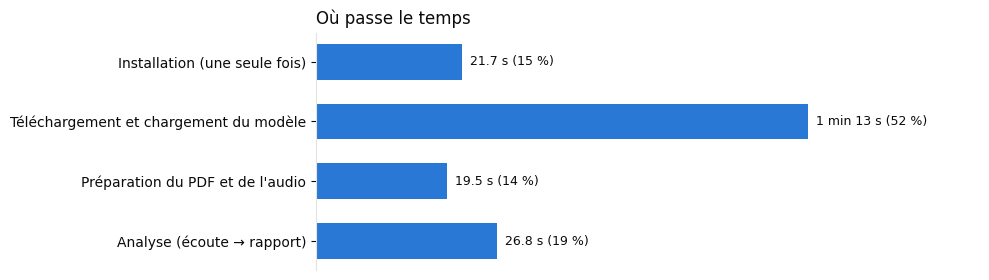

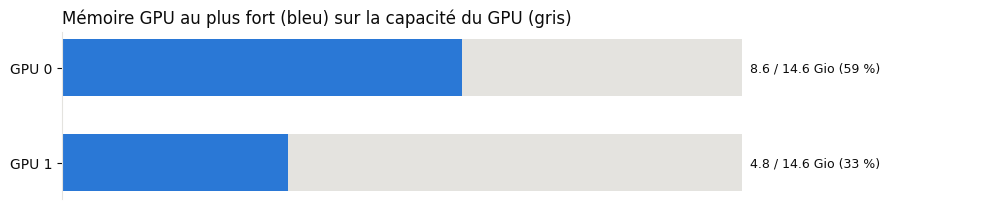

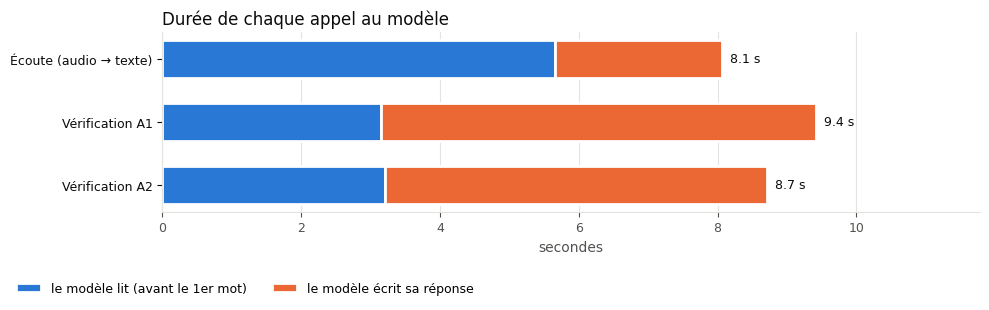

💾 Enregistré dans /kaggle/working/analyse_phi4/resultats : performance.json, performance_etapes.csv, performance_inferences.csv (+ bilan ajouté à rapport_analyse.md) — pour les tableaux complets : AFFICHER_DETAILS = True en haut de cette cellule


In [17]:
# Bilan des performances, en clair : une phrase, des réponses simples avec 🟢 🟡 🔴, deux ou trois graphiques.
# Même cellule dans les notebooks Phi-4 et Qwen. Les mesures détaillées restent enregistrées (performance.json, .csv) :
# ce sont elles que lit la comparaison des deux modèles.
AFFICHER_DETAILS = False      # True : affiche aussi les tableaux complets et les courbes GPU au fil du temps

PERF.fin(afficher=False)      # ferme une étape restée ouverte (cellule interrompue)


def taux_erreur_mots(reference, hypothese):
    """WER = (substitutions + suppressions + insertions) / nombre de mots de la référence (distance d'édition sur les mots)."""
    normaliser = lambda t: re.findall(r"[a-z0-9]+", sans_accents((t or "").lower()))
    ref, hyp = normaliser(reference), normaliser(hypothese)
    d = list(range(len(hyp) + 1))
    for i in range(1, len(ref) + 1):
        precedent, d[0] = d[0], i
        for j in range(1, len(hyp) + 1):
            courant = d[j]
            d[j] = min(d[j] + 1, d[j - 1] + 1, precedent + (ref[i - 1] != hyp[j - 1]))
            precedent = courant
    return d[len(hyp)] / max(len(ref), 1)


def feu_memoire(pct):
    if not np.isfinite(pct):
        return "—"
    if pct < 75:
        return "🟢 large marge"
    if pct < 90:
        return "🟡 marge faible"
    return "🔴 à la limite : risque de manque de mémoire"


def feu_wer(pct):
    if pct <= 10:
        return "🟢 très fidèle"
    if pct <= 25:
        return "🟡 quelques mots déformés"
    return "🔴 peu fidèle : le modèle a mal entendu"


def equivalent_led(wh):
    """Ordre de grandeur parlant : durée d'éclairage d'une ampoule LED de 10 W avec la même énergie."""
    minutes = wh / 10 * 60
    if minutes < 1:
        return f"{minutes * 60:.0f} s"
    return f"{minutes:.0f} min" if minutes < 90 else f"{minutes / 60:.1f} h"


# ---------- 1. Les chiffres ----------
NOM_MODELE = ("Phi-4-multimodal" if "phi" in MODEL_ID.lower() else "Qwen2.5-Omni-7B" if "qwen" in MODEL_ID.lower()
              else MODEL_ID)
etapes, appels = PERF.etapes, PERF.inferences
GROUPES = [("Installation (une seule fois)", {"Installation des bibliothèques"}),
           ("Téléchargement et chargement du modèle", {"Téléchargement du modèle", "Chargement du modèle sur les GPU"}),
           ("Préparation du PDF et de l'audio", {"Lecture du PDF", "Conversion des pages en images", "Préparation de l'audio"})]
CONNUES = set().union(*(noms for _, noms in GROUPES))
TEMPS_PAR_GROUPE = [(titre, sum(e["duree_s"] for e in etapes if e["etape"] in noms)) for titre, noms in GROUPES]
TEMPS_PAR_GROUPE.append(("Analyse (écoute → rapport)", sum(e["duree_s"] for e in etapes if e["etape"] not in CONNUES)))
duree_totale = sum(d for _, d in TEMPS_PAR_GROUPE)
duree_analyse = TEMPS_PAR_GROUPE[-1][1]
energie_totale = sum(e.get("energie_gpu_wh") or 0 for e in etapes)
energie_analyse = sum(e.get("energie_gpu_wh") or 0 for e in etapes if e["etape"] not in CONNUES)
n_aff = len(ANALYSE)
n_avec_verdict = n_aff - len(SANS_VERDICT)
par_affirmation = duree_analyse / max(n_aff, 1)

MEMOIRE = []
for i in range(PERF.n_gpu):
    total = torch.cuda.get_device_properties(i).total_memory / 2**30
    occupe = _maximum([e.get(f"gpu{i}_occupe_pic_mo", float("nan")) for e in etapes]) / 1024    # vue du pilote
    pytorch = _maximum([e.get(f"gpu{i}_pic_pytorch_mo", float("nan")) for e in etapes]) / 1024
    pic = occupe if np.isfinite(occupe) else pytorch
    MEMOIRE.append({"gpu": i, "total": total, "pic": pic, "pct": 100 * pic / total, "pytorch": pytorch})
gpu_max = max(MEMOIRE, key=lambda m: m["pct"] if np.isfinite(m["pct"]) else -1, default=None)
MEMOIRE_MESUREE = gpu_max is not None and np.isfinite(gpu_max["pic"])

ecoutes = [r for r in appels if r["inference"].startswith("Écoute")]
verifs = [r for r in appels if r["inference"].startswith("Vérification")]
lecture_totale = sum(r["ttft_s"] for r in appels if np.isfinite(r["ttft_s"]))
ecriture_totale = sum(r["ecriture_s"] for r in appels if np.isfinite(r["ecriture_s"]))
TEXTE_ENTENDU = globals().get("ECOUTE_BRUTE") or " ".join(a["affirmation"] for a in ANALYSE if a["affirmation"])
WER = 100 * taux_erreur_mots(TRANSCRIPTION_REFERENCE, TEXTE_ENTENDU) if TRANSCRIPTION_REFERENCE else None

RESUME_PERFORMANCE = {
    "modele": MODEL_ID, "duree_totale_notebook_s": duree_totale, "duree_analyse_s": duree_analyse,
    "duree_par_affirmation_s": par_affirmation, "duree_calcul_modele_s": sum(r["duree_s"] for r in appels),
    "appels_modele": len(appels), "lecture_entree_s": lecture_totale, "ecriture_s": ecriture_totale,
    "tokens_lus": sum(r["tokens_entree"] for r in appels), "tokens_ecrits": sum(r["tokens_sortie"] for r in appels),
    "energie_gpu_totale_wh": energie_totale, "energie_gpu_analyse_wh": energie_analyse,
    **{f"gpu{m['gpu']}_pic_gio": m["pic"] for m in MEMOIRE}, **{f"gpu{m['gpu']}_pic_pct": m["pct"] for m in MEMOIRE},
    "affirmations": n_aff, "affirmations_avec_verdict": n_avec_verdict, "erreurs_detectees": len(ERREURS),
    "analyse_complete": ANALYSE_COMPLETE,
}
if WER is not None:
    RESUME_PERFORMANCE["wer_ecoute_pct"] = WER

# ---------- 2. Le bilan en clair ----------
phrase = (f"**En une phrase :** {NOM_MODELE} a analysé ton explication de {DUREE_AUDIO_S:.0f} s en "
          f"**{duree_lisible(duree_analyse)}** ({n_aff} affirmation(s), soit {duree_lisible(par_affirmation)} chacune), "
          + (f"avec au plus **{gpu_max['pic']:.1f} Gio** de mémoire sur un GPU de {gpu_max['total']:.0f} Gio, et "
             if MEMOIRE_MESUREE else "et ")
          + f"**{energie_analyse:.1f} Wh** d'énergie (autant qu'une ampoule LED de 10 W allumée {equivalent_led(energie_analyse)}).")

lignes = [("⏱️", "Combien de temps a pris l'analyse ?",
           f"{duree_lisible(duree_analyse)} ({len(appels)} appel(s) au modèle)",
           f"{duree_lisible(par_affirmation)} par affirmation")]
if ecoutes:                                     # notebook Phi-4 : écoute séparée
    t_ecoute = sum(r["duree_s"] for r in ecoutes)
    vitesse_ecoute = DUREE_AUDIO_S / max(t_ecoute, 1e-6)          # > 1 : plus rapide que le temps réel
    lignes.append(("🎧", "L'écoute est-elle plus rapide que l'audio ?", f"{t_ecoute:.1f} s pour {DUREE_AUDIO_S:.1f} s d'audio",
                   f"🟢 oui, {vitesse_ecoute:.1f}× plus rapide" if vitesse_ecoute >= 1
                   else f"🟡 non, {1 / vitesse_ecoute:.1f}× plus lente"))
if verifs:
    plus_longue = max(verifs, key=lambda r: r["duree_s"])
    lignes.append(("🔎", "Combien de temps pour vérifier une affirmation ?",
                   f"{_moyenne([r['duree_s'] for r in verifs]):.0f} s en moyenne ({len(verifs)} vérifications)",
                   f"la plus longue : {plus_longue['inference'].replace('Vérification ', '')} ({plus_longue['duree_s']:.0f} s)"))
if not ecoutes and not verifs and appels:       # notebook Qwen : une seule requête
    lignes.append(("🧠", "Comment se répartit le travail du modèle ?",
                   f"{lecture_totale:.0f} s pour lire + {ecriture_totale:.0f} s pour écrire",
                   "il lit toutes les pages et l'audio avant d'écrire le 1er mot"))
if MEMOIRE_MESUREE:
    lignes.append(("💾", "La mémoire GPU suffit-elle ?",
                   " · ".join(f"GPU {m['gpu']} : {m['pic']:.1f} / {m['total']:.1f} Gio ({m['pct']:.0f} %)" for m in MEMOIRE),
                   feu_memoire(gpu_max["pct"])))
lignes.append(("⚡", "Combien d'énergie ?", f"{energie_analyse:.1f} Wh pour l'analyse ({energie_totale:.1f} Wh en tout)",
               f"≈ une ampoule LED de 10 W pendant {equivalent_led(energie_analyse)}"))
lignes.append(("✅", "Le modèle a-t-il jugé chaque affirmation ?", f"{n_avec_verdict} / {n_aff}",
               "🟢 oui" if ANALYSE_COMPLETE else "🔴 non : analyse incomplète, « 0 erreur » ne prouverait rien"))
lignes.append(("❌", "Combien d'erreurs a-t-il trouvées ?", f"{len(ERREURS)}", "le détail est dans le rapport ci-dessus"))
if WER is not None:
    lignes.append(("🎧", "A-t-il bien entendu ce que tu as dit ?", f"{WER:.0f} % de mots différents (WER)", feu_wer(WER)))
else:
    lignes.append(("🎧", "A-t-il bien entendu ce que tu as dit ?", "non mesuré",
                   "écris ce que tu as dit dans TRANSCRIPTION_REFERENCE (section 1) pour le savoir"))
TABLEAU = ("| | Question | Réponse | Ce que ça veut dire |\n|---|---|---|---|\n"
           + "\n".join(f"| {icone} | {q} | {r} | {s} |" for icone, q, r, s in lignes))

groupe_max, duree_max = max(TEMPS_PAR_GROUPE, key=lambda g: g[1])
a_retenir = [f"La plus grosse part du temps : **{groupe_max.lower()}** ({100 * duree_max / max(duree_totale, 1e-6):.0f} % "
             f"sur {duree_lisible(duree_totale)})."
             + (" Elle ne se refait pas si tu relances seulement l'analyse dans la même session."
                if groupe_max != "Analyse (écoute → rapport)" else "")]
if appels and lecture_totale + ecriture_totale > 0:
    part_lecture = 100 * lecture_totale / (lecture_totale + ecriture_totale)
    a_retenir.append(f"Dans les appels au modèle, **{part_lecture:.0f} %** du temps sert à **lire** l'entrée (pages, audio, "
                     f"texte) et {100 - part_lecture:.0f} % à **écrire** la réponse"
                     + (" : moins de pages, ou des pages plus petites, accélèrent la lecture." if part_lecture > 50 else
                        " : des réponses plus courtes accélèrent l'écriture."))
if MEMOIRE_MESUREE:
    a_retenir.append(f"Mémoire : {feu_memoire(gpu_max['pct'])} (pic à {gpu_max['pct']:.0f} % sur le GPU {gpu_max['gpu']})"
                     + (" : tu pourrais augmenter la résolution des pages." if gpu_max["pct"] < 75 else "."))
a_retenir.append("Résultat : " + ("🟢 chaque affirmation a reçu un verdict." if ANALYSE_COMPLETE else
                                  f"🔴 {len(SANS_VERDICT)} affirmation(s) sans verdict : lis la réponse brute du modèle."))
BILAN_MD = (f"### 📊 Bilan des performances — {NOM_MODELE}\n\n{phrase}\n\n{TABLEAU}\n\n#### À retenir\n\n"
            + "\n".join(f"- {p}" for p in a_retenir))
display(Markdown(BILAN_MD))

# ---------- 3. Deux ou trois graphiques simples ----------
def _barres_simples(titre, etiquettes, valeurs, textes, hauteur_barre=0.45):
    fig, ax = plt.subplots(figsize=(10, hauteur_barre * len(etiquettes) + 1.1))
    barres = ax.barh(etiquettes[::-1], valeurs[::-1], color=COULEURS_GPU[0], height=0.6)
    for b, t in zip(barres, textes[::-1]):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, "  " + t, va="center", fontsize=9, color=ENCRE)
    ax.set_xlim(0, (max(valeurs) or 1) * 1.35)
    ax.set_title(titre, loc="left", color=ENCRE, fontsize=12)
    PERF._style(ax)
    ax.tick_params(axis="y", colors=ENCRE, labelsize=10)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    plt.tight_layout()
    plt.show()


groupes_non_vides = [(t, d) for t, d in TEMPS_PAR_GROUPE if d > 0]
_barres_simples("Où passe le temps", [t for t, _ in groupes_non_vides], [d for _, d in groupes_non_vides],
                [f"{duree_lisible(d)} ({100 * d / max(duree_totale, 1e-6):.0f} %)" for _, d in groupes_non_vides])

# Mémoire : barre grise = capacité du GPU, barre bleue = pic atteint
if MEMOIRE_MESUREE:
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(MEMOIRE) + 1.1))
    noms_gpu = [f"GPU {m['gpu']}" for m in MEMOIRE][::-1]
    ax.barh(noms_gpu, [m["total"] for m in MEMOIRE][::-1], color=GRILLE, height=0.6)
    barres = ax.barh(noms_gpu, [m["pic"] if np.isfinite(m["pic"]) else 0 for m in MEMOIRE][::-1], color=COULEURS_GPU[0], height=0.6)
    for b, m in zip(barres, MEMOIRE[::-1]):
        ax.text(m["total"], b.get_y() + b.get_height() / 2, f"  {m['pic']:.1f} / {m['total']:.1f} Gio ({m['pct']:.0f} %)",
                va="center", fontsize=9, color=ENCRE)
    ax.set_xlim(0, max(m["total"] for m in MEMOIRE) * 1.35)
    ax.set_title("Mémoire GPU au plus fort (bleu) sur la capacité du GPU (gris)", loc="left", color=ENCRE, fontsize=12)
    PERF._style(ax)
    ax.tick_params(axis="y", colors=ENCRE, labelsize=10)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    plt.tight_layout()
    plt.show()

if len(appels) > 1:          # plusieurs appels (Phi-4) : lequel prend le plus de temps, et pourquoi
    noms = [r["inference"] for r in appels][::-1]
    lire = [r["ttft_s"] if np.isfinite(r["ttft_s"]) else 0 for r in appels][::-1]
    ecrire = [r["ecriture_s"] if np.isfinite(r["ecriture_s"]) else 0 for r in appels][::-1]
    hauteur = 0.45 * len(noms) + 1.8
    fig, ax = plt.subplots(figsize=(10, hauteur))
    ax.barh(noms, lire, color=COULEURS_GPU[0], height=0.6, label="le modèle lit (avant le 1er mot)",
            edgecolor="white", linewidth=2)
    ax.barh(noms, ecrire, left=lire, color=COULEURS_GPU[1], height=0.6, label="le modèle écrit sa réponse",
            edgecolor="white", linewidth=2)
    for y, (l, e) in enumerate(zip(lire, ecrire)):
        ax.text(l + e, y, f"  {duree_lisible(l + e)}", va="center", fontsize=9, color=ENCRE)
    ax.set_xlim(0, (max(l + e for l, e in zip(lire, ecrire)) or 1) * 1.25)
    ax.set_title("Durée de chaque appel au modèle", loc="left", color=ENCRE, fontsize=12)
    fig.legend(loc="lower left", bbox_to_anchor=(0.01, 0.01), ncol=2, frameon=False, fontsize=9)
    PERF._style(ax)
    ax.tick_params(axis="y", colors=ENCRE, labelsize=9)
    ax.set_xlabel("secondes", color=ENCRE_SECONDAIRE)
    plt.tight_layout(rect=(0, 0.4 / hauteur, 1, 1))
    plt.show()

# ---------- 4. Détails (facultatifs) ----------
if AFFICHER_DETAILS:
    display(Markdown("### Détails : chaque étape du notebook"))
    display(PERF.tableau_etapes())
    display(Markdown("### Détails : chaque appel au modèle"))
    display(PERF.tableau_inferences())
    display(Markdown("### Détails : ressources GPU au fil du temps"))
    PERF.graphique_chronologie()

# ---------- 5. Sauvegarde ----------
PERF.sauvegarder(DOSSIER_RESULTATS, RESUME_PERFORMANCE)
with open(CHEMIN_RAPPORT, encoding="utf-8") as f:
    rapport = f.read().split("\n\n---\n\n## Performances")[0]      # cellule relancée : on remplace l'ancien bilan
with open(CHEMIN_RAPPORT, "w", encoding="utf-8") as f:
    f.write(rapport + "\n\n---\n\n## Performances\n\n" + BILAN_MD.split("\n\n", 1)[1] + "\n")
print(f"💾 Enregistré dans {DOSSIER_RESULTATS} : performance.json, performance_etapes.csv, performance_inferences.csv "
      f"(+ bilan ajouté à {os.path.basename(CHEMIN_RAPPORT)})"
      + ("" if AFFICHER_DETAILS else " — pour les tableaux complets : AFFICHER_DETAILS = True en haut de cette cellule"))